# کنترل مغناطیسی ذره در کانال دوبعدی با کوپل هیدرودینامیکی دوطرفه

نسخهٔ مستقل و تکمیل‌شدهٔ فایل پیوست؛ **حل عددی مستقیم، بدون PINN**.
هستهٔ حل سیال، کرنل گاوسی و نیروی اصطکاکی از فایل شما حفظ شده‌اند؛ نیروی مغناطیسی، کنترل میدان، آزمون‌ها و نمایش‌ها اضافه شده‌اند.

**اجرا:** `Run all`. فقط NumPy، Matplotlib و Pillow لازم‌اند. CuPy اختیاری است و در صورت موجودبودن CUDA خودکار انتخاب می‌شود.
نصب خودکار یا دانلود داده انجام نمی‌شود. اجرای ذخیره‌شدهٔ این فایل روی CPU انجام شده؛ مسیر GPU اینجا آزمایش نشده است.

این نسخه یک ذرهٔ مغناطیس‌پذیرِ خنثی و با پاسخ القایی خطی را در سیال همگن، غیرمغناطیسی و نارسانا مدل می‌کند.
میدان خارجی تحلیلی و تجویزشده است؛ هندسهٔ سیم‌پیچ و بازخورد ذره به میدان الکترومغناطیسی حل نمی‌شوند.
تعداد ذرات نسبت به فایل پایه تغییر نکرده است: **یک ذره در هر اجرا**.


## معادلات و محل درست اعمال نیرو

$$m\dot{\mathbf V}=\mathbf F_{drag}+\mathbf F_{mag},\qquad \dot{\mathbf q}=\mathbf V,$$
$$\mathbf F_{drag}=\gamma(J\mathbf u-\mathbf V),\qquad
\mathbf f_{particle\to fluid}=-S\mathbf F_{drag}.$$

فقط عکس نیروی هیدرودینامیکی وارد سیال می‌شود. عکس نیروی مغناطیسی روی منبع خارجی میدان است؛ واردکردن مستقیمِ $-S\mathbf F_{mag}$ به سیال در این مدل درست نیست.
نیروی مغناطیسی ابتدا ذره را حرکت می‌دهد و اثر آن از طریق درگ، دوطرفه به سیال می‌رسد.

برای دوقطبی القاییِ همسانگرد و پاسخ خطی:

$$\mathbf F_{mag}=\frac{\alpha}{2}\nabla|\mathbf B|^2
=\alpha\mathbf G^T\mathbf B,\quad G_{ij}=\partial_jB_i,\quad
U_{mag}=-\frac{\alpha}{2}|\mathbf B|^2.$$

این نیرو برای ذرهٔ خنثی است؛ $q\mathbf V\times\mathbf B$ به مدل اضافه نشده است.
میدان یکنواخت گرادیان ندارد و در این مدل نیروی انتقالی ایجاد نمی‌کند.
برگرداندن علامت **کل میدان** نیز جهت نیروی القایی را برنمی‌گرداند، چون نیرو به مربع میدان وابسته است؛ برای هدایت، گرادیان را کنترل می‌کنیم.

تمام کمیت‌ها مانند فایل اولیه **بی‌بعد و برای واحد عمق** هستند؛ مقادیر B بر حسب تسلا نیستند.
اگر $\beta'$ قطبش‌پذیری مغناطیسی به‌ازای واحد عمق باشد، آنگاه
$\alpha=\beta' B_{ref}^2/(\rho_{ref}U_{ref}^2L_{ref}^2)$.
$\alpha$ یک حساسیت مغناطیسی خام نیست و $\sigma$ نیز قطر یک کرهٔ واقعی را تعیین نمی‌کند.


## میدان خارجی و کنترل

با $k=2\pi/L$ و $z=k(y-H/2)$، میدان زیر را به کار می‌بریم:

$$B_x=b\cos\theta+A\sin[k(x-x_c)]\cosh z,$$
$$B_y=b\sin\theta-A\cos[k(x-x_c)]\sinh z.$$

این میدان در راستای x تناوبی است و در هر لحظه $\nabla\cdot\mathbf B=0$ و $\nabla\times\mathbf B=0$ دارد.
در مشتق‌های مکانی، کنترل‌های $A,x_c,\theta$ ثابت نگه داشته می‌شوند.

برای کنترل عمودی، $\theta=\pi/2$ و $x_c=x_p$ انتخاب می‌شود؛ دامنهٔ A از نیروی درخواستی محاسبه و به `max_amplitude` محدود می‌شود.
سپس نیروی **واقعی** دوباره از B و مشتق‌های آن به دست می‌آید و معادلهٔ حرکت انتگرال‌گیری می‌شود؛ مکان ذره به هدف تحمیل نمی‌شود.
کنترل‌کنندهٔ PD دارای جبران درگ است و اطلاع دقیق از وضعیت و سیال را فرض می‌کند؛ این یک کنترل‌کنندهٔ ایده‌آلِ میدان است، نه طراحی سخت‌افزار سیم‌پیچ.
کنترل عمودی، مسیر x را مستقلاً تعیین نمی‌کند؛ حرکت طولی از جریان و دینامیک ذره به دست می‌آید.

موازنهٔ انرژی مکانیکی، توان مغناطیسی $\mathbf F_{mag}\cdot\mathbf V$ را شامل می‌شود.
در میدان متغیر یا کنترل‌شده، انرژی مکانیکی به‌علاوهٔ پتانسیل مغناطیسی الزاماً ثابت نیست؛ منبع خارجی می‌تواند کار انجام دهد.


## ۱. هستهٔ اصلی سیال و آزمون‌های آن

In [1]:
"""One regularized frictional point degree of freedom coupled to 2D Navier-Stokes.
All quantities are nondimensional and per unit out-of-plane depth.
CPU: NumPy. Optional CUDA: CuPy, same float64 discretization. No PINN training.
"""
import os, json, time, math, zipfile
from pathlib import Path
from dataclasses import dataclass, asdict, replace
import numpy as np
import matplotlib
if os.environ.get('MPLBACKEND'):
    matplotlib.use(os.environ['MPLBACKEND'])
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

# No downloads or package installation are performed automatically.
xp = np
BACKEND = 'NumPy / CPU'
if os.environ.get('TWOWAY_BACKEND', 'auto').lower() != 'cpu':
    try:
        import cupy as cp
        if cp.cuda.runtime.getDeviceCount() > 0:
            xp = cp
            BACKEND = 'CuPy / CUDA'
    except (ImportError, RuntimeError, OSError):
        pass

def host(a):
    return xp.asnumpy(a) if xp is not np else np.asarray(a)

def scalar(a):
    return float(a.item()) if hasattr(a, 'item') else float(a)

def sync():
    if xp is not np:
        xp.cuda.Stream.null.synchronize()

@dataclass(frozen=True)
class Config:
    L: float = 4.0
    H: float = 1.0
    nx: int = 192
    ny: int = 48
    nu: float = 0.05
    rho: float = 1.0
    umax: float = 1.0
    sigma: float = 0.085      # Fixed physical regularization width, NOT grid spacing.
    mass: float = 0.025      # Mass of the point degree of freedom; no displaced volume.
    gamma: float = 0.15      # Friction coefficient of THIS regularized model.
    x0: float = 0.65
    y0: float = 0.42
    vx0: float = 1.8
    vy0: float = 0.32
    T: float = 1.2
    dt: float = 0.0015
    frames: int = 61




class Channel:
    def __init__(self, c):
        self.c = c
        self.dx, self.dy = c.L/c.nx, c.H/c.ny
        self.area = self.dx*self.dy
        self.drive = 8*c.nu*c.umax/c.H**2
        self.xu = xp.arange(c.nx, dtype=xp.float64)*self.dx
        self.xv = self.xu + self.dx/2
        self.yu = (xp.arange(c.ny, dtype=xp.float64)+0.5)*self.dy
        self.yv = xp.arange(c.ny+1, dtype=xp.float64)*self.dy
        kx = xp.arange(c.nx//2+1, dtype=xp.float64)
        ky = xp.arange(2*c.ny, dtype=xp.float64)
        self.lam = (-4*(xp.sin(xp.pi*ky/(2*c.ny))/self.dy)**2)[:,None] + \
                   (-4*(xp.sin(xp.pi*kx/c.nx)/self.dx)**2)[None,:]
        self.lam[0,0] = 1.0
        y = self.yu[:,None]
        # Exact steady solution of the cell-centred ghost-wall Laplacian.
        # Its difference from continuum Poiseuille is O(dy**2).
        self.base = xp.broadcast_to(c.umax*(4*y*(c.H-y)/c.H**2 + (self.dy/c.H)**2),
                                    (c.ny,c.nx)).copy()

    def initial(self):
        c = self.c
        return (self.base.copy(), xp.zeros((c.ny+1,c.nx), dtype=xp.float64),
                xp.array([c.x0,c.y0],dtype=xp.float64),
                xp.array([c.vx0,c.vy0],dtype=xp.float64))

    def divergence(self, u, v):
        return (xp.roll(u,-1,axis=1)-u)/self.dx + (v[1:]-v[:-1])/self.dy

    def project(self, au, av):
        # P = I - G (D G)^(-1) D. Neumann-y / periodic-x pressure solve.
        b = self.divergence(au,av)
        b = b - b.mean()
        even = xp.concatenate((b,b[::-1]), axis=0)
        ph = xp.fft.rfft2(even)/self.lam
        ph[0,0] = 0.0
        p = xp.fft.irfft2(ph, s=even.shape)[:self.c.ny]
        pu = au - (p-xp.roll(p,1,axis=1))/self.dx
        pv = av.copy()
        pv[1:-1] -= (p[1:]-p[:-1])/self.dy
        pv[0] = 0.0
        pv[-1] = 0.0
        return pu,pv,p

    def kernels(self, q):
        # Discrete Gaussian, normalized separately on each MAC component grid.
        # Zero weights at constrained v wall faces maintain the adjoint identity.
        def weight(xs, ys, wall=False):
            rx = (xs-q[0]+self.c.L/2) % self.c.L-self.c.L/2
            ry = ys-q[1]
            w = xp.exp(-0.5*((ry[:,None]/self.c.sigma)**2 +
                              (rx[None,:]/self.c.sigma)**2))
            if wall:
                w[0]=0.0
                w[-1]=0.0
            return w / w.sum()     # w = K * dx * dy, hence sum(w)=1.
        return weight(self.xu,self.yu),weight(self.xv,self.yv,True)

    def transport(self, u, v):
        # Centred conservative MAC fluxes; no flow across either solid wall.
        u_e = (u+xp.roll(u,-1,axis=1))/2
        flux_uu = u_e*u_e
        u_y = xp.zeros_like(v)
        u_y[1:-1] = (u[:-1]+u[1:])/2
        v_x = (v+xp.roll(v,1,axis=1))/2
        flux_uv = u_y*v_x
        advu = (flux_uu-xp.roll(flux_uu,1,axis=1))/self.dx + \
               (flux_uv[1:]-flux_uv[:-1])/self.dy
        v_y = (v[:-1]+v[1:])/2
        advv = xp.zeros_like(v)
        advv[1:-1] = (xp.roll(flux_uv[1:-1],-1,axis=1)-flux_uv[1:-1])/self.dx + \
                     (v_y[1:]**2-v_y[:-1]**2)/self.dy
        # Odd ghost u enforces zero tangential velocity at the wall itself.
        ug = xp.concatenate((-u[:1],u,-u[-1:]),axis=0)
        lapu = (xp.roll(u,1,axis=1)-2*u+xp.roll(u,-1,axis=1))/self.dx**2 + \
               (ug[2:]-2*u+ug[:-2])/self.dy**2
        lapv = xp.zeros_like(v)
        lapv[1:-1] = (xp.roll(v[1:-1],1,axis=1)-2*v[1:-1]+ \
                      xp.roll(v[1:-1],-1,axis=1))/self.dx**2 + \
                     (v[2:]-2*v[1:-1]+v[:-2])/self.dy**2
        return advu,advv,lapu,lapv

    def rhs(self, state, feedback=True):
        u,v,q,V = state
        c = self.c
        wu,wv = self.kernels(q)
        J = xp.stack(((wu*u).sum(),(wv*v).sum()))
        F = c.gamma*(J-V)           # Force ON the particle.
        if feedback:
            fu = -F[0]*wu/self.area # Force density ON the fluid.
            fv = -F[1]*wv/self.area
        else:
            fu,fv = xp.zeros_like(u),xp.zeros_like(v)
        au,av,lu,lv = self.transport(u,v)
        ru = -au + c.nu*lu + self.drive + fu/c.rho
        rv = -av + c.nu*lv + fv/c.rho
        ru,rv,p = self.project(ru,rv)
        dstate = (ru,rv,V,F/c.mass)
        return dstate,(F,J,fu,fv,p,lu,lv)

    def diagnostics(self, state, details, feedback):
        u,v,q,V = state
        F,J,fu,fv,p,lu,lv = details
        c = self.c
        integral_force = self.area*xp.stack((fu.sum(),fv.sum()))
        force_error = xp.linalg.norm(integral_force+F) if feedback else xp.asarray(0.)
        power = self.area*((u*fu).sum()+(v*fv).sum()) + (F*V).sum()
        predicted_power = -c.gamma*((J-V)**2).sum()
        power_error = abs(power-predicted_power) if feedback else xp.asarray(0.)
        external_x = c.rho*self.drive*c.L*c.H + c.rho*c.nu*self.area*lu.sum()
        # Global x momentum: pressure/convection integrate to zero in periodic x.
        energy_rate = c.rho*self.drive*self.area*u.sum() + \
            c.rho*c.nu*self.area*((u*lu).sum()+(v*lv).sum()) + power
        return xp.stack((force_error,power_error,external_x,energy_rate,
                         xp.linalg.norm(F),xp.linalg.norm(J-V)))

    def energy(self, state):
        u,v,q,V = state
        return self.c.rho*self.area*((u*u).sum()+(v*v).sum())/2 + \
               self.c.mass*(V*V).sum()/2

    def momentum_x(self,state):
        u,v,q,V=state
        return self.c.rho*self.area*u.sum()+self.c.mass*V[0]

    def run(self, feedback=True, quiet=False):
        c = self.c
        n = max(c.frames-1, math.ceil(c.T/c.dt/(c.frames-1)-1e-12)*(c.frames-1))
        dt = c.T/n
        # Conservative explicit stability bounds, also checked during the run.
        diffusion = c.nu*dt*(1/self.dx**2+1/self.dy**2)
        assert diffusion < 0.45, f'Diffusion bound {diffusion:.3g}: reduce dt.'
        assert c.sigma/min(self.dx,self.dy)>=2, 'Resolve sigma by at least two cells.'
        assert c.mass>0 and c.gamma>0
        state = self.initial()
        E0, P0 = scalar(self.energy(state)), scalar(self.momentum_x(state))
        keep = set(np.unique(np.rint(np.linspace(0,n,c.frames)).astype(int)))
        records=[]; frames=[]; diags=[]
        accumulated_impulse=xp.asarray(0.,dtype=xp.float64)
        accumulated_work=xp.asarray(0.,dtype=xp.float64)
        sync(); tic=time.perf_counter()
        for it in range(n+1):
            # Reuse k1 both for snapshots and for the first RK stage.
            k1,detail1=self.rhs(state,feedback)
            if it in keep:
                u,v,q,V=state
                uc=(u+xp.roll(u,-1,axis=1))/2
                vc=(v[:-1]+v[1:])/2
                frames.append(np.stack((host(uc),host(vc),host(detail1[4]))))
                d1=self.diagnostics(state,detail1,feedback)
                records.append([it*dt,*host(q),*host(V),*host(detail1[0]),*host(detail1[1]),
                                scalar(xp.abs(self.divergence(u,v)).max()),
                                scalar(self.momentum_x(state))-P0-scalar(accumulated_impulse),
                                scalar(self.energy(state))-E0-scalar(accumulated_work)])
                diags.append(host(d1))
                # Stop instead of silently clipping, reflecting, or accepting NaNs.
                if not np.isfinite(frames[-1]).all():
                    raise FloatingPointError('Non-finite solution: reduce dt.')
                if not 4*c.sigma < scalar(q[1]) < c.H-4*c.sigma:
                    raise ValueError('Particle too close to a wall for this demonstration.')
                speed=max(scalar(xp.abs(u).max()),abs(scalar(V[0])))
                vertical=max(scalar(xp.abs(v).max()),abs(scalar(V[1])))
                assert dt*(speed/self.dx+vertical/self.dy)<0.45, 'Advection bound: reduce dt.'
                if not quiet and (it==0 or it==n):
                    print(('two-way' if feedback else 'one-way'),f'{it}/{n} steps')
            if it==n:
                break
            middle=tuple(s+dt*k/2 for s,k in zip(state,k1))
            k2,detail2=self.rhs(middle,feedback)
            dm=self.diagnostics(middle,detail2,feedback)
            accumulated_impulse+=dt*dm[2]
            accumulated_work+=dt*dm[3]
            state=tuple(s+dt*k for s,k in zip(state,k2))
        sync()
        return {'records':np.array(records),'fields':np.array(frames),
                'diagnostics':np.array(diags),'settings':asdict(c),'dt_used':dt,
                'feedback':feedback,'seconds':time.perf_counter()-tic}

def structural_checks(c):
    s=Channel(c)
    rng=np.random.default_rng(124)
    u=xp.asarray(rng.normal(size=(c.ny,c.nx)))
    v=xp.asarray(rng.normal(size=(c.ny+1,c.nx)));v[0]=0.;v[-1]=0.
    u,v,p=s.project(u,v)
    u2,v2,_=s.project(u,v)
    q=xp.array([0.017,c.y0]);V=xp.array([1.4,0.2])
    state=(u,v,q,V)
    rhs,details=s.rhs(state,True)
    d=s.diagnostics(state,details,True)
    a,b,lu,lv=s.transport(u,v)
    convection_work=scalar(s.area*((u*a).sum()+(v*b).sum()))
    w1,w2=s.kernels(q)
    result={
        'projection_divergence':scalar(xp.abs(s.divergence(u,v)).max()),
        'projection_idempotence':max(scalar(xp.abs(u2-u).max()),scalar(xp.abs(v2-v).max())),
        'kernel_normalization':max(abs(scalar(w1.sum())-1),abs(scalar(w2.sum())-1)),
        'interaction_force_residual':scalar(d[0]),
        'interaction_power_residual':scalar(d[1]),
        'convective_energy_residual':abs(convection_work),
    }
    limits={k:1e-9 for k in result}
    for key,value in result.items():
        assert value<limits[key], (key,value)
    return result


def shear_test(ny=48, T=0.2):
    # Independent continuum benchmark: decaying sine shear, zero drive/particle.
    c=Config(nx=4*ny,ny=ny,dt=0.0006)
    s=Channel(c)
    u=xp.broadcast_to(xp.sin(xp.pi*s.yu/c.H)[:,None],(ny,c.nx)).copy()
    v=xp.zeros((ny+1,c.nx))
    # Linear shear uses the SAME transport and projection routines as production.
    def derivative(z):
        a,b,lu,lv=s.transport(z,v)
        r,_,_=s.project(-a+c.nu*lu,xp.zeros_like(v))
        return r
    n=math.ceil(T/c.dt);dt=T/n
    for _ in range(n):
        k=derivative(u)
        u+=dt*derivative(u+dt*k/2)
    exact=xp.sin(xp.pi*s.yu/c.H)[:,None]*xp.exp(-c.nu*(xp.pi/c.H)**2*T)
    return scalar(xp.linalg.norm(u-exact)/xp.linalg.norm(xp.broadcast_to(exact,u.shape)))


def compare_runs(coarse,fine):
    a,b=coarse['records'],fine['records']
    # Both use exactly the same physical times at all saved frames.
    assert np.allclose(a[:,0],b[:,0],atol=1e-12)
    # Cell-centred fine data restrict to coarse cell centres by 2x2 averaging.
    base_c=host(Channel(Config(**coarse['settings'])).base)
    base_f=host(Channel(Config(**fine['settings'])).base)
    duc=coarse['fields'][:,:2].copy();duc[:,0]-=base_c
    duf=fine['fields'][:,:2].copy();duf[:,0]-=base_f
    duf=duf.reshape(len(b),2,coarse['settings']['ny'],2,
                    coarse['settings']['nx'],2).mean(axis=(3,5))
    flow_error=np.linalg.norm(duc-duf)/max(np.linalg.norm(duf),1e-15)
    return {'trajectory_max':float(np.linalg.norm(a[:,1:3]-b[:,1:3],axis=1).max()),
            'disturbance_relative_L2_space_time':float(flow_error)}

## ۲. میدان، نیروی مغناطیسی و حل‌گر دوطرفهٔ تکمیل‌شده

In [2]:
# Prescribed magnetostatic field + induced-dipole force; ideal bounded field control.
@dataclass(frozen=True)
class MagneticConfig:
    mode: str = 'target'     # off, uniform, static, target, wave
    alpha: float = 0.025     # Effective dimensionless polarizability per unit depth.
    bias: float = 1.0       # B / B_ref; NOT tesla.
    bias_angle: float = math.pi/2
    amplitude: float = 0.35 # Static spatial-harmonic amplitude.
    phase_x: float = 0.0
    max_amplitude: float = 1.5
    target_y: float = 0.58
    guide_time: float = 1.0
    wave_amplitude: float = 0.06
    kp: float = 0.6         # Position gain, units force / length in this scaling.
    kd: float = 0.25        # Velocity gain, units force / velocity.


def harmonic_field(q, c, m, amplitude=None, phase=None, angle=None):
    """Return B and G[i,j]=dB_i/dx_j. Analytic, curl-free and divergence-free.
    Periodic in x. External controls are held fixed in ALL spatial derivatives.
    Compatible with NumPy arrays and CuPy arrays, including batched (...,2) q.
    """
    A=m.amplitude if amplitude is None else amplitude
    phase=m.phase_x if phase is None else phase
    theta=m.bias_angle if angle is None else angle
    k=2*xp.pi/c.L;z=k*(q[...,1]-c.H/2);a=k*(q[...,0]-phase)
    sh,ch=xp.sinh(z),xp.cosh(z);sn,cs=xp.sin(a),xp.cos(a)
    bx=m.bias*math.cos(theta)+A*sn*ch
    by=m.bias*math.sin(theta)-A*cs*sh
    aa=A*k*cs*ch;bb=A*k*sn*sh
    B=xp.stack((bx,by),axis=-1)
    G=xp.stack((xp.stack((aa,bb),axis=-1),xp.stack((bb,-aa),axis=-1)),axis=-2)
    return B,G


def dipole_force(B,G,alpha):
    # F = alpha/2 grad(B.B) = alpha G^T B. No q(v cross B) Lorentz term.
    return alpha*xp.einsum('...ij,...i->...j',G,B)


def reference_motion(t,c,m):
    """Reference y, dy/dt, d2y/dt2, no modification of simulated positions."""
    if m.mode=='wave':
        # Smooth zero initial position/velocity/acceleration offset, both directions.
        w=2*math.pi/c.T
        y=c.y0+m.wave_amplitude*(math.sin(w*t)/2-math.sin(2*w*t)/4)
        v=m.wave_amplitude*w*(math.cos(w*t)-math.cos(2*w*t))/2
        a=m.wave_amplitude*w*w*(-math.sin(w*t)/2+math.sin(2*w*t))
        return y,v,a
    T=m.guide_time;s=min(max(t/T,0.),1.)
    if t>=T:return m.target_y,0.,0.
    h=10*s**3-15*s**4+6*s**5
    dh=30*s*s-60*s**3+30*s**4
    ddh=60*s-180*s*s+120*s**3
    z=s-6*s**3+8*s**4-3*s**5
    dz=1-18*s*s+32*s**3-15*s**4
    ddz=-36*s+96*s*s-60*s**3
    dy=m.target_y-c.y0
    return c.y0+dy*h+c.vy0*T*z,dy*dh/T+c.vy0*dz,dy*ddh/T**2+c.vy0*ddz/T


def magnetic_control(q,V,Fdrag,t,c,m):
    """Infer bounded analytic-field controls, then evaluate the ACTUAL field force.
    Exact qx phase tracking is an ideal actuator assumption, not a coil solver.
    """
    if m.mode not in ('off','uniform','static','target','wave'):
        raise ValueError('Unknown magnetic mode: '+m.mode)
    if m.mode=='off':
        return xp.zeros(2),xp.zeros(2),xp.asarray(0.),xp.asarray(0.),xp.asarray(0.),0.,0.,0.,False
    A=xp.asarray(0. if m.mode=='uniform' else m.amplitude)
    phase=xp.asarray(m.phase_x);angle=m.bias_angle
    yref,vref,aref=reference_motion(t,c,m)
    desired=xp.asarray(0.);saturated=xp.asarray(False)
    if m.mode in ('target','wave'):
        if m.alpha<=0 or m.bias<=0:raise ValueError('Control needs alpha>0 and bias>0.')
        desired=c.mass*aref-Fdrag[1]+m.kp*(yref-q[1])+m.kd*(vref-V[1])
        phase=q[0]                   # Spatial phase centered on current particle.
        angle=math.pi/2
        k=2*xp.pi/c.L;z=k*(q[1]-c.H/2)
        C=desired/(m.alpha*k*xp.cosh(z));s=xp.sinh(z)
        disc=m.bias**2+4*s*C
        root=xp.sqrt(xp.maximum(disc,0.))
        raw=-2*C/(m.bias+root)       # Stable quadratic root, continuous at s=0.
        A=xp.clip(raw,-m.max_amplitude,m.max_amplitude)
        saturated=(disc<0)|(xp.abs(raw)>m.max_amplitude)
    B,G=harmonic_field(q,c,m,A,phase,angle)
    F=dipole_force(B,G,m.alpha)
    U=-m.alpha*xp.sum(B*B)/2
    return F,B,A,phase,U,yref,vref,desired,saturated


MAG_COLUMNS=['t','x','y','vx','vy','Fdrag_x','Fdrag_y','Jux','Juy',
 'max_div','momentum_x_residual','energy_residual','Fmag_x','Fmag_y',
 'Bx','By','amplitude','phase_x','y_ref','vy_ref','magnetic_potential',
 'desired_Fy','actuator_saturated','magnetic_power','cumulative_magnetic_work']

class MagneticChannel(Channel):
    def __init__(self,c,mag=None):
        super().__init__(c);self.mag=mag or MagneticConfig()
        if c.frames<2 or c.T<=0 or c.dt<=0:raise ValueError('Invalid time settings.')
        if self.mag.alpha<0 or self.mag.max_amplitude<=0:raise ValueError('Invalid magnetic settings.')
        if self.mag.mode in ('target','wave'):
            if self.mag.guide_time<=0:raise ValueError('guide_time must be positive.')
            if self.mag.mode=='target' and not 4*c.sigma<self.mag.target_y<c.H-4*c.sigma:
                raise ValueError('Target must stay >4 sigma from each wall.')
    def rhs_at(self,state,t,feedback=True):
        d,b=super().rhs(state,feedback)
        fm=magnetic_control(state[2],state[3],b[0],t,self.c,self.mag)
        d=(d[0],d[1],d[2],(b[0]+fm[0])/self.c.mass)
        return d,(b,fm)
    def audit_at(self,state,details,feedback):
        b,fm=details;d=super().diagnostics(state,b,feedback).copy()
        # Magnet reaction is on the external field source, NOT directly on the fluid.
        d[2]+=fm[0][0]
        d[3]+=xp.dot(fm[0],state[3])
        if not feedback:d[2]+=b[0][0] # Missing hydro reaction is an external term in one-way control.
        return d
    def run(self,feedback=True,quiet=False):
        c=self.c;m=self.mag
        n=max(c.frames-1,math.ceil(c.T/c.dt/(c.frames-1)-1e-12)*(c.frames-1));dt=c.T/n
        if c.nu*dt*(1/self.dx**2+1/self.dy**2)>=.45:raise ValueError('Reduce dt: diffusion bound.')
        if c.sigma/max(self.dx,self.dy)<2:raise ValueError('Resolve sigma with >=2 cells in BOTH directions.')
        if c.mass<=0 or c.gamma<=0:raise ValueError('Mass and gamma must be positive.')
        state=self.initial();E0=scalar(self.energy(state));P0=scalar(self.momentum_x(state))
        impulse=xp.asarray(0.,dtype=xp.float64);work=xp.asarray(0.,dtype=xp.float64);mag_work=xp.asarray(0.,dtype=xp.float64)
        keep=set(np.linspace(0,n,c.frames).round().astype(int));records=[];fields=[];diags=[]
        sync();tic=time.perf_counter()
        for it in range(n+1):
            t=it*dt;k1,dd1=self.rhs_at(state,t,feedback)
            if it in keep:
                u,v,q,V=state;b,fm=dd1;Fmag,B,A,phase,U,yr,vr,des,sat=fm
                if not all(np.isfinite(host(z)).all() for z in state):raise FloatingPointError('Non-finite state.')
                if not 4*c.sigma<scalar(q[1])<c.H-4*c.sigma:
                    raise ValueError('Particle enters near-wall region. Reduce force/target excursion; no clipping applied.')
                cfl=dt*(max(scalar(xp.abs(u).max()),abs(scalar(V[0])))/self.dx+
                        max(scalar(xp.abs(v).max()),abs(scalar(V[1])))/self.dy)
                if cfl>=.45:raise ValueError('Reduce dt: advection bound.')
                uc=(u+xp.roll(u,-1,axis=1))/2;vc=(v[1:]+v[:-1])/2
                fields.append(np.stack((host(uc),host(vc),host(b[4]))))
                records.append([t,*host(q),*host(V),*host(b[0]),*host(b[1]),
                    scalar(xp.abs(self.divergence(u,v)).max()),scalar(self.momentum_x(state))-P0-scalar(impulse),
                    scalar(self.energy(state))-E0-scalar(work),*host(Fmag),*host(B),scalar(A),scalar(phase),
                    float(yr),float(vr),scalar(U),scalar(des),float(scalar(sat)),scalar(xp.dot(Fmag,V)),scalar(mag_work)])
                diags.append(host(self.audit_at(state,dd1,feedback)))
            if it==n:break
            mid=tuple(s+dt*k/2 for s,k in zip(state,k1))
            k2,dd2=self.rhs_at(mid,t+dt/2,feedback)
            dm=self.audit_at(mid,dd2,feedback)
            impulse+=dt*dm[2];work+=dt*dm[3];mag_work+=dt*xp.dot(dd2[1][0],mid[3])
            state=tuple(s+dt*k for s,k in zip(state,k2))
        sync()
        result={'records':np.array(records),'fields':np.array(fields),'diagnostics':np.array(diags),
          'settings':asdict(c),'magnetic_settings':asdict(m),'dt_used':dt,'feedback':feedback,
          'seconds':time.perf_counter()-tic}
        if not quiet:print(m.mode,'two-way' if feedback else 'one-way',f'{result["seconds"]:.2f}s')
        return result

## ۳. آزمون‌های مستقل، بازتولید جواب قبلی، موازنه‌ها و ریزکردن شبکه/زمان

In [3]:
def force_law_tests(c):
    rng=np.random.default_rng(8103);points=xp.asarray(np.column_stack((rng.uniform(0,c.L,35),rng.uniform(.35,.65,35))))
    m=MagneticConfig(mode='static',bias_angle=.47,amplitude=.4,phase_x=.27)
    B,G=harmonic_field(points,c,m);F=dipole_force(B,G,m.alpha)
    eps=1e-5;numG=[];gradU=[]
    for j in range(2):
        e=xp.zeros(2);e[j]=eps
        bp,_=harmonic_field(points+e,c,m);bm,_=harmonic_field(points-e,c,m)
        numG.append((bp-bm)/(2*eps))
        gradU.append((-m.alpha*(bp*bp).sum(-1)/2+m.alpha*(bm*bm).sum(-1)/2)/(2*eps))
    numericG=xp.stack(numG,axis=-1);numericF=-xp.stack(gradU,axis=-1)
    Bu,Gu=harmonic_field(points,c,replace(m,amplitude=0.))
    # A uniform field can be arbitrarily strong but has zero translational force.
    Bneg=-B;Gneg=-G
    shifted=points.copy();shifted[:,0]+=c.L;Bs,Gs=harmonic_field(shifted,c,m)
    return {
      'field_derivative_fd_error':scalar(xp.abs(G-numericG).max()),
      'force_vs_potential_gradient_error':scalar(xp.abs(F-numericF).max()),
      'finite_difference_divB':scalar(xp.abs(numericG[:,0,0]+numericG[:,1,1]).max()),
      'finite_difference_curlB':scalar(xp.abs(numericG[:,1,0]-numericG[:,0,1]).max()),
      'uniform_field_force':scalar(xp.abs(dipole_force(Bu,Gu,m.alpha)).max()),
      'zero_alpha_force':scalar(xp.abs(dipole_force(B,G,0.)).max()),
      'reverse_all_B_force_change':scalar(xp.abs(dipole_force(Bneg,Gneg,m.alpha)-F).max()),
      'double_field_force_scaling_error':scalar(xp.abs(dipole_force(2*B,2*G,m.alpha)-4*F).max()),
      'x_periodicity_error':max(scalar(xp.abs(Bs-B).max()),scalar(xp.abs(Gs-G).max()))}


def analytic_particle_test():
    """Independent exact solution: frozen fluid at rest, 1D quadrupole field.
    B=(G*x, B0-G*y), start x=vx=0 => x stays 0, F_y=alpha*(G²*y-G*B0).
    Same magnetic force routine, compared with closed-form exponential solution.
    """
    m=.025;gamma=.15;alpha=.025;g=.7;b0=.8;T=.3;y0=.1;v0=.02
    r1=(-gamma+math.sqrt(gamma**2+4*m*alpha*g*g))/(2*m)
    r2=(-gamma-math.sqrt(gamma**2+4*m*alpha*g*g))/(2*m)
    yeq=b0/g;a=(v0-r2*(y0-yeq))/(r1-r2);b=y0-yeq-a
    exact=np.array([yeq+a*math.exp(r1*T)+b*math.exp(r2*T),a*r1*math.exp(r1*T)+b*r2*math.exp(r2*T)])
    def rhs(z):
        B=xp.array([0.,b0-g*z[0]]);G=xp.array([[g,0.],[0.,-g]])
        f=scalar(dipole_force(B,G,alpha)[1])
        return np.array([z[1],(f-gamma*z[1])/m])
    errs=[]
    for n in (100,200):
        z=np.array([y0,v0]);dt=T/n
        for _ in range(n):z+=dt*rhs(z+dt*rhs(z)/2)
        errs.append(float(np.linalg.norm(z-exact)))
    return {'coarse_error':errs[0],'fine_error':errs[1],'error_ratio':errs[0]/errs[1]}


def refinement_difference(a,b):
    # a is 2x coarser than b; subtract each mesh's own discrete Poiseuille baseline.
    fa=a['fields'][:,:2].copy();fb=b['fields'][:,:2].copy()
    ca=Config(**a['settings']);cb=Config(**b['settings'])
    fa[:,0]-=host(Channel(ca).base);fb[:,0]-=host(Channel(cb).base)
    fb=fb.reshape(len(fb),2,ca.ny,2,ca.nx,2).mean(axis=(3,5))
    return {'disturbance_relative_L2':float(np.linalg.norm(fa-fb)/max(np.linalg.norm(fb),1e-15)),
      'path_max':float(np.linalg.norm(a['records'][:,1:3]-b['records'][:,1:3],axis=1).max())}


def magnetic_experiment(c,mag,out):
    out=Path(out);out.mkdir(parents=True,exist_ok=True);tic=time.perf_counter()
    force=force_law_tests(c);analytic=analytic_particle_test();structure=structural_checks(c)
    shear24=shear_test(24);shear48=shear_test(48)
    # Regression against the attached ORIGINAL solver, with exactly its settings.
    regc=replace(Config(),nx=96,ny=24,T=.12,frames=13,dt=.002)
    original=Channel(regc).run(True,True)
    zero=MagneticChannel(regc,replace(mag,mode='off')).run(True,True)
    regression=max(float(abs(original['records']-zero['records'][:,:12]).max()),
                   float(abs(original['fields']-zero['fields']).max()))
    cases={}
    cases['off']=MagneticChannel(c,replace(mag,mode='off')).run()
    cases['uniform']=MagneticChannel(c,replace(mag,mode='uniform')).run(quiet=True)
    cases['up']=MagneticChannel(c,replace(mag,mode='target',target_y=c.H*.58)).run()
    cases['down']=MagneticChannel(c,replace(mag,mode='target',target_y=c.H*.42)).run()
    cases['wave']=MagneticChannel(c,replace(mag,mode='wave')).run()
    cases['static']=MagneticChannel(c,replace(mag,mode='static',bias_angle=.4)).run()
    cases['limited']=MagneticChannel(c,replace(mag,mode='target',target_y=c.H*.58,max_amplitude=.02)).run(quiet=True)
    one=MagneticChannel(c,replace(mag,mode='target',target_y=c.H*.58)).run(False,True)
    coarse=MagneticChannel(replace(c,nx=c.nx//2,ny=c.ny//2,dt=2*cases['up']['dt_used']),
                          replace(mag,mode='target',target_y=c.H*.58)).run(quiet=True)
    fine_time=MagneticChannel(replace(c,dt=cases['up']['dt_used']/2),
                             replace(mag,mode='target',target_y=c.H*.58)).run(quiet=True)
    grid=refinement_difference(coarse,cases['up'])
    a=cases['up']['fields'][:,:2].copy();base=host(Channel(c).base)
    a[:,0]-=base
    td=float(np.linalg.norm(fine_time['fields'][:,:2]-cases['up']['fields'][:,:2])/max(np.linalg.norm(a),1e-15))
    tp=float(np.linalg.norm(fine_time['records'][:,1:3]-cases['up']['records'][:,1:3],axis=1).max())
    metrics={}
    for name,o in cases.items():
        r=o['records'];d=o['diagnostics'];delta=o['fields'][:,:2].copy();delta[:,0]-=base
        met={'max_divergence':float(r[:,9].max()),'momentum_x_residual':float(abs(r[:,10]).max()),
          'energy_residual':float(abs(r[:,11]).max()),'drag_reaction_residual':float(d[:,0].max()),
          'drag_power_identity_residual':float(d[:,1].max()),'max_fluid_disturbance':float(np.linalg.norm(delta,axis=1).max()),
          'final_y':float(r[-1,2]),'saturated_saved_fraction':float(r[:,22].mean()),
          'max_magnetic_force':float(np.linalg.norm(r[:,12:14],axis=1).max())}
        if name in ('up','down','wave'):
            met['max_tracking_error']=float(abs(r[:,2]-r[:,18]).max())
            met['final_tracking_error']=float(abs(r[-1,2]-r[-1,18]))
            met['max_force_command_error']=float(abs(r[:,13]-r[:,21]).max())
        metrics[name]=met
    # Static-control energy INCLUDING magnetic potential must obey external drive/viscous/drag work only.
    st=cases['static']['records'];dt=cases['static']['dt_used']
    # Integrate Fmag.V independently from fine saved frames for an additional work-potential check.
    trapezoid=getattr(np,'trapezoid',None) or np.trapz
    static_work_saved=trapezoid(st[:,23],st[:,0]);static_work=st[-1,24];potential_change=st[-1,20]-st[0,20]
    static_work_residual=float(abs(static_work+potential_change))
    sym=float(abs(cases['up']['records'][:,2]+cases['down']['records'][:,2]-c.H).max())
    uniform_change=max(float(abs(cases['off']['records'][:,:14]-cases['uniform']['records'][:,:14]).max()),
                       float(abs(cases['off']['fields']-cases['uniform']['fields']).max()))
    delta_one=one['fields'][:,:2].copy();delta_one[:,0]-=base
    max_one=float(abs(delta_one).max())
    report={'backend':BACKEND,'original_notebook_zero_field_regression':regression,'force_law_tests':force,
      'analytic_particle_benchmark':analytic,'original_structural_checks':structure,
      'shear_relative_L2_24':shear24,'shear_relative_L2_48':shear48,'case_metrics':metrics,
      'uniform_vs_off_solution_change':uniform_change,'up_down_reflection_error':sym,
      'static_magnetic_work_plus_potential_change':static_work_residual,
      'static_saved_sample_work_potential_error':float(abs(static_work_saved+potential_change)),
      'up_vs_off_max_fluid_change':float(np.linalg.norm(cases['up']['fields'][:,:2]-cases['off']['fields'][:,:2],axis=1).max()),
      'one_way_max_fluid_change':max_one,'grid_refinement':grid,
      'time_refinement_disturbance_relative_L2':td,'time_refinement_path_max':tp,
      'up_vs_off_final_y_change':float(cases['up']['records'][-1,2]-cases['off']['records'][-1,2]),
      'down_vs_off_final_y_change':float(cases['down']['records'][-1,2]-cases['off']['records'][-1,2])}
    checks={
      'magnetic_force_matches_potential_gradient':force['force_vs_potential_gradient_error']<1e-8,
      'analytic_field_derivatives':force['field_derivative_fd_error']<1e-7,
      'solenoidal_field_fd':force['finite_difference_divB']<1e-7,
      'curl_free_field_fd':force['finite_difference_curlB']<1e-7,
      'uniform_field_has_no_force':force['uniform_field_force']<1e-14,
      'zero_polarizability_has_no_force':force['zero_alpha_force']<1e-14,
      'field_sign_reversal_does_not_reverse_induced_force':force['reverse_all_B_force_change']<1e-14,
      'field_strength_squared_scaling':force['double_field_force_scaling_error']<1e-14,
      'magnetic_x_periodicity':force['x_periodicity_error']<1e-12,
      'analytic_particle_second_order':analytic['fine_error']<1e-5 and analytic['error_ratio']>3.7,
      'original_solver_regression':regression<1e-11,
      'uniform_field_same_motion_as_off':uniform_change<1e-11,
      'independent_shear_benchmark':shear48<1e-4 and shear24/shear48>3.5,
      'incompressible_all_cases':max(m['max_divergence'] for m in metrics.values())<1e-9,
      'hydrodynamic_action_reaction_all_cases':max(m['drag_reaction_residual'] for m in metrics.values())<1e-11,
      'hydrodynamic_power_identity_all_cases':max(m['drag_power_identity_residual'] for m in metrics.values())<1e-11,
      'momentum_includes_external_magnet_force':max(m['momentum_x_residual'] for m in metrics.values())<1e-9,
      'energy_includes_magnetic_work':max(m['energy_residual'] for m in metrics.values())<1e-5,
      'static_force_work_potential_check':static_work_residual<1e-5,
      'bidirectional_steering':report['up_vs_off_final_y_change']>.05 and report['down_vs_off_final_y_change']<-.05,
      'reflection_symmetry':sym<1e-9,
      'targets_and_wave_tracked':max(metrics[n]['max_tracking_error'] for n in ('up','down','wave'))<.003,
      'bounded_field_command_achieved':max(metrics[n]['max_force_command_error'] for n in ('up','down','wave'))<1e-10,
      'one_way_control_no_fluid_feedback':max_one<1e-10,
      'magnetic_two_way_fluid_response':metrics['up']['max_fluid_disturbance']>1e-3,
      'magnetic_steering_changes_fluid_vs_unactuated':report['up_vs_off_max_fluid_change']>1e-3,
      'limited_actuator_saturates_and_cannot_teleport':metrics['limited']['saturated_saved_fraction']>.1 and abs(metrics['limited']['final_y']-.58)>.03,
      'spatial_refinement_disturbance':grid['disturbance_relative_L2']<.12,
      'spatial_refinement_particle':grid['path_max']<.005,
      'time_refinement_disturbance':td<.01,
      'time_refinement_particle':tp<1e-4,
    }
    report['checks']=checks;report['all_passed']=all(checks.values());report['compute_seconds']=time.perf_counter()-tic
    for name,o in {**cases,'one_way_up':one}.items():
        np.savez_compressed(out/(name+'.npz'),records=o['records'],fields=o['fields'],diagnostics=o['diagnostics'])
        np.savetxt(out/(name+'.csv'),o['records'],delimiter=',',header=','.join(MAG_COLUMNS),comments='')
    (out/'settings.json').write_text(json.dumps({'fluid':asdict(c),'magnetic':asdict(mag)},indent=2))
    (out/'verification.json').write_text(json.dumps(report,indent=2))
    print(json.dumps(report,indent=2))
    return cases,one,report

## ۴. توابع نمایش نتایج و ساخت انیمیشن آفلاین

In [4]:
def plot_magnetic_results(cases,selected,report,out):
    out=Path(out);out.mkdir(exist_ok=True,parents=True)
    c=Config(**selected['settings']);s=Channel(c);r=selected['records'];t=r[:,0]
    colors={'off':'#7f8c8d','up':'#007f9f','down':'#d17732','wave':'#8552a8','limited':'#c44b60'}
    plt.rcParams.update({'font.size':10,'axes.titlesize':11,'figure.facecolor':'white','savefig.facecolor':'white'})
    fig,ax=plt.subplots(2,3,figsize=(15,8),layout='constrained')
    for name in ('off','up','down','wave','limited'):
        a=cases[name]['records'];co=colors[name]
        ax[0,0].plot(a[:,1],a[:,2],label=name,color=co,lw=2)
        ax[0,1].plot(a[:,0],a[:,2],label=name,color=co,lw=2)
        if name in ('up','down','wave'):ax[0,1].plot(a[:,0],a[:,18],ls='--',color=co,alpha=.5)
    ax[0,0].set(title='Computed paths; prescribed field acts through force',xlabel='x / H',ylabel='y / H');ax[0,0].legend()
    ax[0,1].set(title='Actual y (solid) and reference (dashed)',xlabel='time',ylabel='y / H');ax[0,1].legend()
    ax[0,2].plot(t,r[:,6],label='hydrodynamic Fy',color='#007f9f')
    ax[0,2].plot(t,r[:,13],label='magnetic Fy',color='#d17732')
    ax[0,2].plot(t,r[:,6]+r[:,13],label='total Fy',color='#8552a8')
    ax[0,2].set(title='Selected case: particle forces',xlabel='time',ylabel='force per unit depth');ax[0,2].legend()
    ax[1,0].plot(t,r[:,16],label='spatial harmonic amplitude A',color='#007f9f')
    limit=selected['magnetic_settings']['max_amplitude']
    ax[1,0].axhline(limit,ls='--',c='#c44b60',label='amplitude bound');ax[1,0].axhline(-limit,ls='--',c='#c44b60')
    ax[1,0].set(title='Selected case: field control (B / B_ref)',xlabel='time',ylabel='A');ax[1,0].legend()
    base=host(s.base)
    for name in ('up','down','wave'):
        delta=cases[name]['fields'][:,:2]-cases['off']['fields'][:,:2]
        ax[1,1].plot(t,np.linalg.norm(delta,axis=1).max(axis=(1,2)),label=name,color=colors[name])
    ax[1,1].set(title='Fluid change caused by magnetic actuation',xlabel='time',ylabel='max |u_actuated − u_off|');ax[1,1].legend()
    ax[1,2].semilogy(t,np.maximum(abs(r[:,10]),1e-18),label='streamwise momentum residual',color='#007f9f')
    ax[1,2].semilogy(t,np.maximum(abs(r[:,11]),1e-18),label='mechanical energy residual',color='#d17732')
    ax[1,2].semilogy(t,np.maximum(r[:,9],1e-18),label='discrete divergence',color='#8552a8')
    ax[1,2].set(title='Budgets include external magnetic force / work',xlabel='time',ylabel='absolute nondimensional residual');ax[1,2].legend(fontsize=8)
    for a in ax.flat:a.grid(alpha=.15)
    fig.savefig(out/'magnetic_control_and_audit.png',dpi=170);plt.close(fig)
    # Field and fluid snapshots for the selected user's actual run.
    mag=MagneticConfig(**selected['magnetic_settings']);i=int(np.argmax(np.linalg.norm(r[:,12:14],axis=1)))
    X,Y=np.meshgrid((np.arange(c.nx)+.5)*s.dx,(np.arange(c.ny)+.5)*s.dy)
    xy=xp.asarray(np.stack((X,Y),axis=-1));theta=math.pi/2 if mag.mode in ('target','wave') else mag.bias_angle
    B,_=harmonic_field(xy,c,mag,r[i,16],r[i,17],theta)
    if mag.mode=='off':B=xp.zeros_like(B)
    B=host(B);delta=selected['fields'][i,:2]-cases['off']['fields'][i,:2]
    fig,axs=plt.subplots(3,1,figsize=(12,8),layout='constrained')
    data=[(np.linalg.norm(B,axis=-1),'External magnetic field |B| / B_ref','viridis'),
          (np.hypot(*selected['fields'][i,:2]),'Computed two-way fluid speed','viridis'),
          (np.hypot(*delta),'Additional fluid change vs no magnetic actuation','magma')]
    for a,(z,title,cm) in zip(axs,data):
        im=a.imshow(z,origin='lower',extent=(0,c.L,0,c.H),cmap=cm,aspect='equal')
        a.plot(r[:i+1,1]%c.L,r[:i+1,2],c='white',lw=1.3)
        a.scatter([r[i,1]%c.L],[r[i,2]],c='#ffcf40',edgecolors='#172b4d',s=65,zorder=4)
        a.set(title=title+f' | t={r[i,0]:.3f}',xlabel='x / H',ylabel='y / H')
        fig.colorbar(im,ax=a,shrink=.8,pad=.02)
    axs[0].quiver(X[::5,::8],Y[::5,::8],B[::5,::8,0],B[::5,::8,1],color='white',scale=25,width=.002)
    fig.savefig(out/'magnetic_field_and_fluid.png',dpi=170);plt.close(fig)
    return out/'magnetic_control_and_audit.png'


def animate_magnetic(cases,selected,out):
    import io,base64
    from PIL import Image
    out=Path(out);c=Config(**selected['settings']);s=Channel(c);m=MagneticConfig(**selected['magnetic_settings'])
    r=selected['records'];off=cases['off'];delta=np.linalg.norm(selected['fields'][:,:2]-off['fields'][:,:2],axis=1)
    X,Y=np.meshgrid((np.arange(c.nx)+.5)*s.dx,(np.arange(c.ny)+.5)*s.dy);xy=xp.asarray(np.stack((X,Y),axis=-1))
    indices=np.unique(np.linspace(0,len(r)-1,61).round().astype(int))
    angle=math.pi/2 if m.mode in ('target','wave') else m.bias_angle
    Bframes=[]
    for i in indices:
        B,_=harmonic_field(xy,c,m,r[i,16],r[i,17],angle)
        Bframes.append(host(B) if m.mode!='off' else np.zeros((c.ny,c.nx,2)))
    bmax=max(float(np.linalg.norm(b,axis=-1).max()) for b in Bframes)
    fig,axs=plt.subplots(2,2,figsize=(13,7.5),layout='constrained')
    ext=(0,c.L,0,c.H)
    imB=axs[0,0].imshow(np.linalg.norm(Bframes[0],axis=-1),origin='lower',extent=ext,aspect='equal',vmin=0,vmax=max(bmax,1e-8),cmap='viridis')
    imD=axs[0,1].imshow(delta[0],origin='lower',extent=ext,aspect='equal',vmin=0,vmax=max(float(delta.max()),1e-8),cmap='magma')
    axs[0,0].set(title='Selected case: external |B| / B_ref',xlabel='x / H',ylabel='y / H')
    axs[0,1].set(title='Selected case: |u_actuated − u_off|',xlabel='x / H',ylabel='y / H')
    fig.colorbar(imB,ax=axs[0,0],shrink=.65);fig.colorbar(imD,ax=axs[0,1],shrink=.65)
    dots=[axs[0,j].plot([],[],'o',ms=7,mfc='#ffcf40',mec='#172b4d')[0] for j in range(2)]
    lines=[];heads=[];tdots=[]
    colors=['#7f8c8d','#007f9f','#d17732','#8552a8']
    for name,col in zip(('off','up','down','wave'),colors):
        a=cases[name]['records'];axs[1,0].plot(a[:,1],a[:,2],c=col,alpha=.15,lw=1)
        line,=axs[1,0].plot([],[],c=col,lw=2,label=name);head,=axs[1,0].plot([],[],'o',c=col,ms=5)
        lines.append(line);heads.append(head)
        axs[1,1].plot(a[:,0],a[:,2],c=col,lw=1.5,label=name)
        if name!='off':axs[1,1].plot(a[:,0],a[:,18],c=col,ls='--',lw=1,alpha=.4)
        tdots.append(axs[1,1].plot([],[],'o',c=col,ms=5)[0])
    axs[1,0].set(xlim=(c.x0-.03,max(v['records'][-1,1] for k,v in cases.items())+.05),ylim=(.39,.61),title='Computed magnetic steering trajectories',xlabel='x / H',ylabel='y / H')
    axs[1,1].set(xlim=(0,c.T),ylim=(.39,.61),title='Actual y (solid), reference (dashed)',xlabel='time',ylabel='y / H')
    for a in axs[1]:a.legend(fontsize=9);a.grid(alpha=.15)
    title=fig.suptitle('',fontsize=13,fontweight='bold');encoded=[];images=[];tic=time.perf_counter()
    for j,i in enumerate(indices):
        imB.set_data(np.linalg.norm(Bframes[j],axis=-1));imD.set_data(delta[i])
        for d in dots:d.set_data([r[i,1]%c.L],[r[i,2]])
        for k,name in enumerate(('off','up','down','wave')):
            a=cases[name]['records'];lines[k].set_data(a[:i+1,1],a[:i+1,2]);heads[k].set_data([a[i,1]],[a[i,2]]);tdots[k].set_data([a[i,0]],[a[i,2]])
        title.set_text(f'Two-way fluid–particle coupling + induced magnetic dipole | t={r[i,0]:.3f}')
        buf=io.BytesIO();fig.savefig(buf,format='png',dpi=82)
        raw=buf.getvalue();encoded.append('data:image/png;base64,'+base64.b64encode(raw).decode())
        images.append(Image.open(io.BytesIO(raw)).convert('RGB'))
    plt.close(fig)
    tmp=out/'magnetic_motion.partial.gif'
    images[0].save(tmp,save_all=True,append_images=images[1:],duration=90,loop=0,optimize=False)
    tmp.replace(out/'magnetic_motion.gif')
    html='''<!doctype html><html><head><meta charset="utf-8"><title>Magnetic particle control</title>
<style>body{font:15px system-ui;background:#fff;color:#203047;margin:10px}main{max-width:1100px;margin:auto}img{width:100%}nav{display:flex;gap:12px;align-items:center}input{flex:1}button{padding:8px}</style></head><body><main><nav><button id="play">Pause</button><input id="time" type="range" min="0" max="LAST" value="0"><span id="count"></span></nav><img id="image" alt="Computed magnetic steering and fluid response"></main>
<script>const frames=FRAMES;let i=0,on=true,last=0;const seek=document.getElementById('time'),pic=document.getElementById('image'),button=document.getElementById('play');function draw(){pic.src=frames[i];seek.value=i;document.getElementById('count').textContent=(i+1)+' / '+frames.length;}button.onclick=()=>{on=!on;button.textContent=on?'Pause':'Play'};seek.oninput=()=>{i=+seek.value;draw()};function tick(t){if(on&&t-last>90){i=(i+1)%frames.length;last=t;draw()}requestAnimationFrame(tick)}draw();requestAnimationFrame(tick);</script></body></html>'''
    html=html.replace('LAST',str(len(encoded)-1)).replace('FRAMES',json.dumps(encoded))
    (out/'magnetic_motion.html').write_text(html)
    print(f'Animation: {len(images)} frames; rendered in {time.perf_counter()-tic:.1f}s')
    return out/'magnetic_motion.html'


def write_magnetic_readme(report,out):
    p=Path(out)/'README.md'
    text=f'''# Magnetic control of a two-way coupled point particle

Run Magnetic_Two_Way_Channel.ipynb from top to bottom. Or run magnetic_channel.py.
Dependencies: Python 3.10+, NumPy, Matplotlib, Pillow. Optional CUDA backend: CuPy.
No previous notebook state, weights, training or internet download is needed.
This is a DIRECT numerical solver, with the unchanged fluid core from the attached
Simple_Two_Way_Point_Particle_Channel (1).ipynb. One particle per run.

PHYSICS
- 2D incompressible Navier–Stokes, periodic x, no-slip y walls, pressure-gradient drive.
- Positive-mass, finite-width frictional point model: Fdrag=gamma*(J u-V).
- Particle: m dV/dt = Fdrag + Fmag. Fluid receives ONLY -S Fdrag.
- Prescribed, current-free, divergence-free external field, analytic and periodic in x.
- Isotropic, instantaneous, UNSATURATED induced-dipole model: Fmag=alpha G^T B
  = alpha/2 grad(|B|^2), U_mag=-alpha |B|^2/2. This is not a charged-particle Lorentz model.
- The carrier is homogeneous, nonmagnetic and nonconducting. No MHD force, coil
  geometry, induced electric currents, field backreaction, magnetic dipole-dipole
  interaction, thermal noise, rotation, magnetic relaxation or wall contact is solved.
- Hydrodynamic two-way feedback is retained. Electromagnetic coupling to the field
  source is prescribed, not self-consistent. Magnet reaction is on that external source.

UNITS AND CALIBRATION
All quantities are NONDIMENSIONAL and per unit depth, as in the original model.
B entries are B/B_ref, not tesla; alpha is not a raw susceptibility. If beta' is the
induced magnetic polarizability per unit depth (m'=beta' B), then
alpha=beta' B_ref^2/(rho_ref U_ref^2 L_ref^2).
For a calibrated weak-response inclusion, beta'=chi_eff V/(mu0*depth), where
chi_eff must include the appropriate contrast/demagnetization. No physical sphere
radius is inferred from the fluid kernel sigma. Physical use needs material and
field scales/calibration; no experimental accuracy is claimed.

CONTROL
Edit the SELECTED_MAG cell in the notebook:
- mode='off': no magnetic force.
- mode='uniform': nonzero uniform B, zero gradient, zero translational force.
- mode='static': fixed analytic field; set amplitude, phase_x and bias_angle.
- mode='target': bounded ideal state feedback guides y to target_y in guide_time.
- mode='wave': bounded ideal state feedback follows a smooth wave reference.
PD control includes drag compensation and assumes exact state/flow information.
Spatial phase follows qx; amplitude comes from an inverse field-force relation.
Actual force is ALWAYS recomputed from the resulting B and G, then integrated.
Positions are never imposed or overwritten. max_amplitude limits the field
actuator, not material magnetization saturation. A too-weak actuator misses the
reference; the limited-actuator demonstration explicitly checks that behavior.
Lateral guidance does not independently prescribe x motion, which is advected.
No real coil currents, sensor noise, current slew limits or coil inductance model.

NUMERICAL CHECKS
Force versus finite-difference potential gradient; field curl/divergence and
periodicity; zero/uniform field; alpha=0; field reversal invariance; quadratic
field scaling; independent analytic magnetic-particle ODE convergence; the original
solver regression; independent shear PDE benchmark; two-way force and power
identities; streamwise momentum including Fmag_x; mechanical energy including
Fmag.V; static-potential work; reflected steering; weak actuator; fixed-sigma
spatial refinement and time-step refinement. The generated verification.json lists
actual results and predeclared thresholds. Do not change thresholds to force PASS.
A two-grid comparison estimates mesh sensitivity; it is not a three-grid proof.
The optional GPU backend is not tested in this supplied CPU execution.

THIS EXECUTION
- All checks passed: {report['all_passed']}
- Number of checks: {len(report['checks'])}
- Compute seconds, all verification cases: {report['compute_seconds']:.2f}
- Zero-field original-code regression: {report['original_notebook_zero_field_regression']:.3g}
- Max tracking error for y=0.58H: {report['case_metrics']['up']['max_tracking_error']:.5g} H
- Fixed-sigma grid disturbance difference: {report['grid_refinement']['disturbance_relative_L2']*100:.4f}%

BACKGROUND SOURCES
- COMSOL Magnetophoretic Force (prescribed external-field force assumptions):
  https://doc.comsol.com/6.4/doc/com.comsol.help.particle/particle_ug_fluid_flow.08.46.html
- Simultaneous Magnetic Particle Imaging and Navigation of large superparamagnetic
  nanoparticles in bifurcation flow experiments (2019), force proportional to
  grad(B^2)/(2 mu0): https://www.sciencedirect.com/science/article/pii/S0304885319320372
The analytic harmonic field and ideal control scheme in this notebook are a
specific demonstrator design, not a claim to reproduce those apparatuses.
'''
    p.write_text(text)

## ۵. اجرای مجموعهٔ بررسی

موارد آزمون شامل میدان خاموش، میدان یکنواخت، میدان ثابت غیریکنواخت، هدایت بالا و پایین، مسیر موجی و میدان ضعیفِ محدودشده است.
حالت `limited` عمداً به هدف نمی‌رسد: این شکستِ قابل‌انتظار کنترل با قدرت ناکافی است و به‌عنوان موفقیت تشکیل مسیر گزارش نمی‌شود.
معیارهای پذیرش پیش از اجرا در کد تعریف شده‌اند. اگر معیاری رد شود، گزارش ذخیره می‌شود و نوت‌بوک پذیرش را اعلام نمی‌کند.

برای آزمایش کنترل متقارن، در این مجموعهٔ نمایشی $y_0=0.5$ و $v_{y0}=0$ انتخاب شده‌اند.
آزمون بازتولید فایل اصلی، جداگانه با شرایط اولیهٔ اصلیِ همان فایل اجرا می‌شود.


In [5]:
CFG = replace(Config(), T=2.0, frames=81, y0=0.5, vy0=0.0)
DEFAULT_MAG = MagneticConfig()
OUT = Path('magnetic_channel_results')
wall_start = time.perf_counter()
cases, one_way_up, report = magnetic_experiment(CFG, DEFAULT_MAG, OUT)
if not report['all_passed']:
    raise RuntimeError('Failed checks: '+str([k for k,v in report['checks'].items() if not v]))

off two-way 16.62s
target two-way 21.56s
target two-way 21.01s
wave two-way 20.94s
static two-way 19.36s
{
  "backend": "CuPy / CUDA",
  "original_notebook_zero_field_regression": 0.0,
  "force_law_tests": {
    "field_derivative_fd_error": 3.050348862387864e-11,
    "force_vs_potential_gradient_error": 1.1114772296982878e-12,
    "finite_difference_divB": 5.551115123125783e-11,
    "finite_difference_curlB": 1.3877787807814457e-11,
    "uniform_field_force": 0.0,
    "zero_alpha_force": 0.0,
    "reverse_all_B_force_change": 0.0,
    "double_field_force_scaling_error": 0.0,
    "x_periodicity_error": 9.43689570931383e-16
  },
  "analytic_particle_benchmark": {
    "coarse_error": 1.7220654467468853e-06,
    "fine_error": 4.275630725660254e-07,
    "error_ratio": 4.027629038241977
  },
  "original_structural_checks": {
    "projection_divergence": 3.730349362740526e-13,
    "projection_idempotence": 2.6645352591003757e-15,
    "kernel_normalization": 2.220446049250313e-16,
    "interac

## ۶. کنترل دلخواه شما — این سلول را تغییر بده

| پارامتر | کارکرد |
|---|---|
| `mode='target'` | هدایت به ارتفاع `target_y` با مسیر مرجع هموار |
| `mode='wave'` | دنبال‌کردن مسیر موجی، با دامنهٔ `wave_amplitude` |
| `mode='static'` | میدان ثابت؛ تنظیم `amplitude`, `phase_x`, `bias_angle` |
| `mode='uniform'` | میدان غیرصفر ولی یکنواخت؛ بدون نیروی انتقالی |
| `mode='off'` | خاموش |
| `alpha` | شدت پاسخ مغناطیسی بی‌بعد ذره |
| `bias` | شدت میدان بایاس بر حسب $B/B_{ref}$ |
| `max_amplitude` | محدودیت دامنهٔ میدان قابل‌کنترل |
| `guide_time` | مدت انتقال هموار به ارتفاع هدف |
| `kp`, `kd` | ضرایب کنترل مکان و سرعت |

برای مثال `target_y=0.56` را امتحان کن. برای کنترل رو به پایین، `target_y=0.42` قرار بده.
هدف باید بیش از چهار پهنای کرنل از دیواره فاصله داشته باشد. کد در ورود به ناحیهٔ نامعتبر توقف می‌کند؛ موقعیت را برش نمی‌دهد و از دیواره بازنمی‌تاباند.
تغییر این سلول و اجرای سلول‌های بعد برای دیدن کنترل جدید کافی است؛ آزمون‌های مجموعهٔ پیش‌فرض، اعتبارسنجی هر تنظیم دلخواه را تضمین نمی‌کنند.


In [6]:
SELECTED_MAG = replace(DEFAULT_MAG,
    mode='target',
    target_y=0.58,
    guide_time=1.0,
    max_amplitude=1.5,
    kp=0.6,
    kd=0.25,
)
selected = MagneticChannel(CFG, SELECTED_MAG).run(feedback=True)
OUT.mkdir(exist_ok=True, parents=True)
np.savez_compressed(OUT/'selected.npz', **{k:selected[k] for k in ('records','fields','diagnostics')})
np.savetxt(OUT/'selected_history.csv', selected['records'], delimiter=',',
           header=','.join(MAG_COLUMNS), comments='')
(OUT/'selected_settings.json').write_text(json.dumps({'fluid':asdict(CFG),'magnetic':asdict(SELECTED_MAG)},indent=2))
rr = selected['records']
print('Selected final y:', rr[-1,2])
print('Actuator saturated fraction at saved times:', rr[:,22].mean())
if SELECTED_MAG.mode in ('target','wave'):
    print('Selected maximum tracking error:', abs(rr[:,2]-rr[:,18]).max())
    print('Selected final tracking error:', abs(rr[-1,2]-rr[-1,18]))

target two-way 21.02s
Selected final y: 0.5799999948676265
Actuator saturated fraction at saved times: 0.0
Selected maximum tracking error: 1.8802575163512358e-07
Selected final tracking error: 5.132373415150937e-09


## ۷. نمودارهای نیرو، کنترل میدان، مسیر ذره و اثر بر سیال

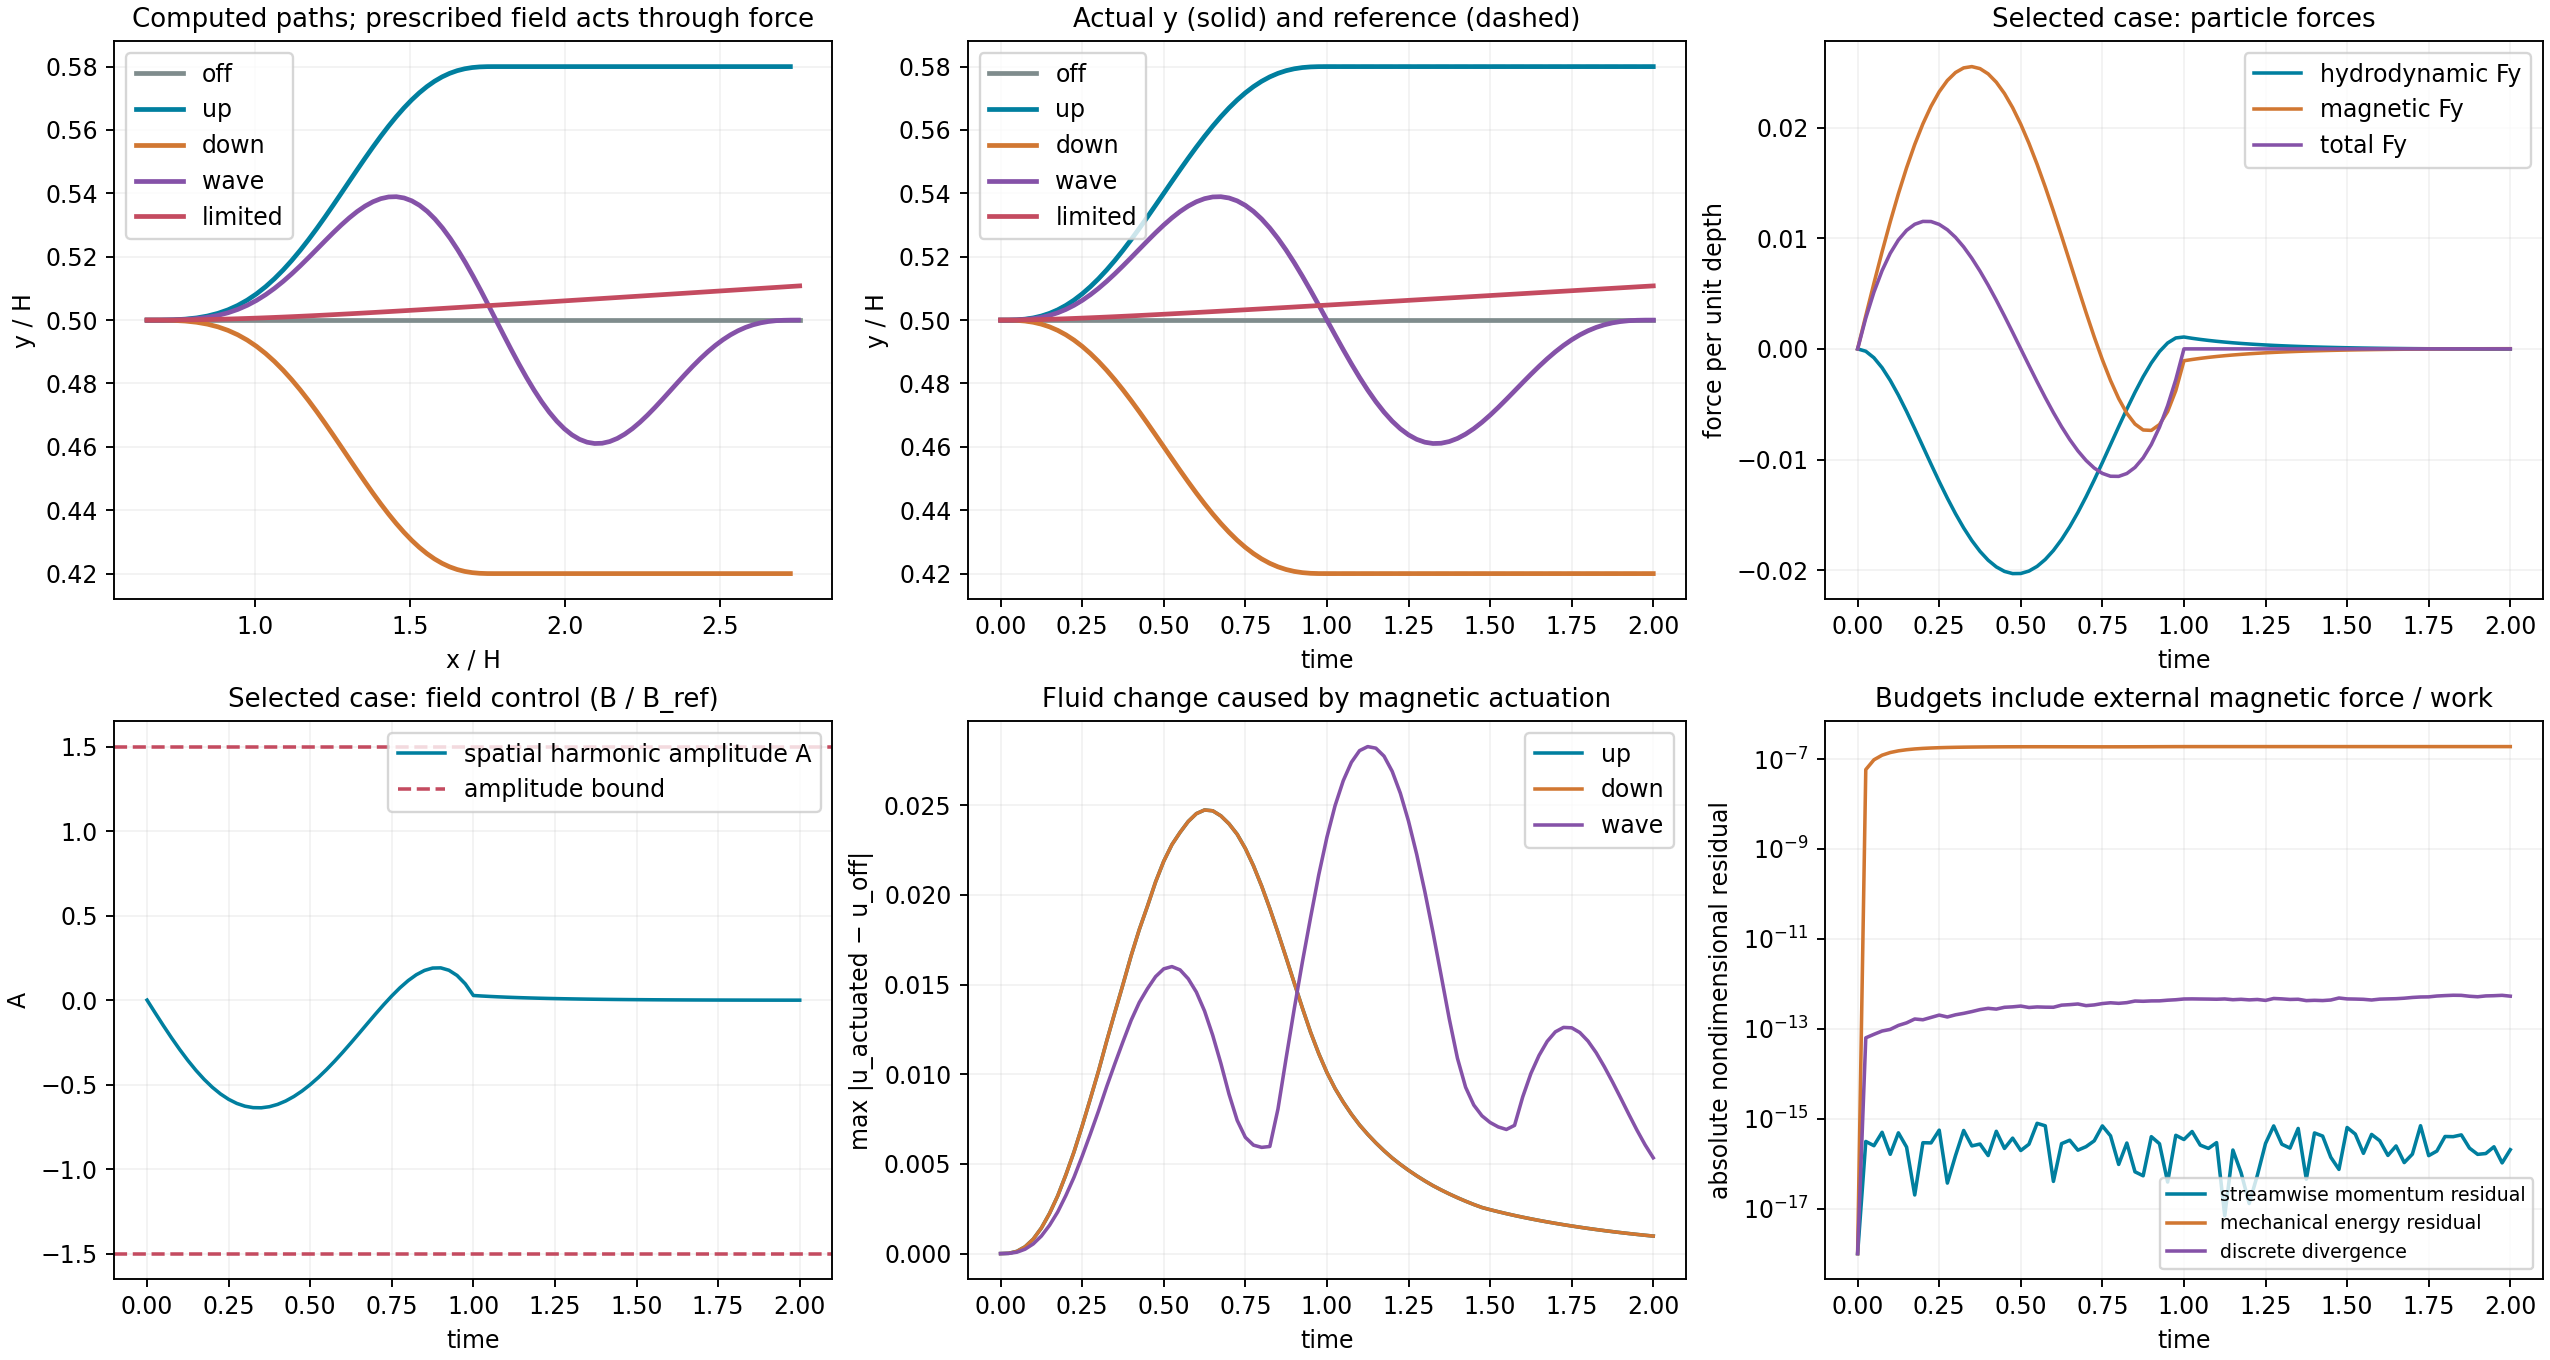

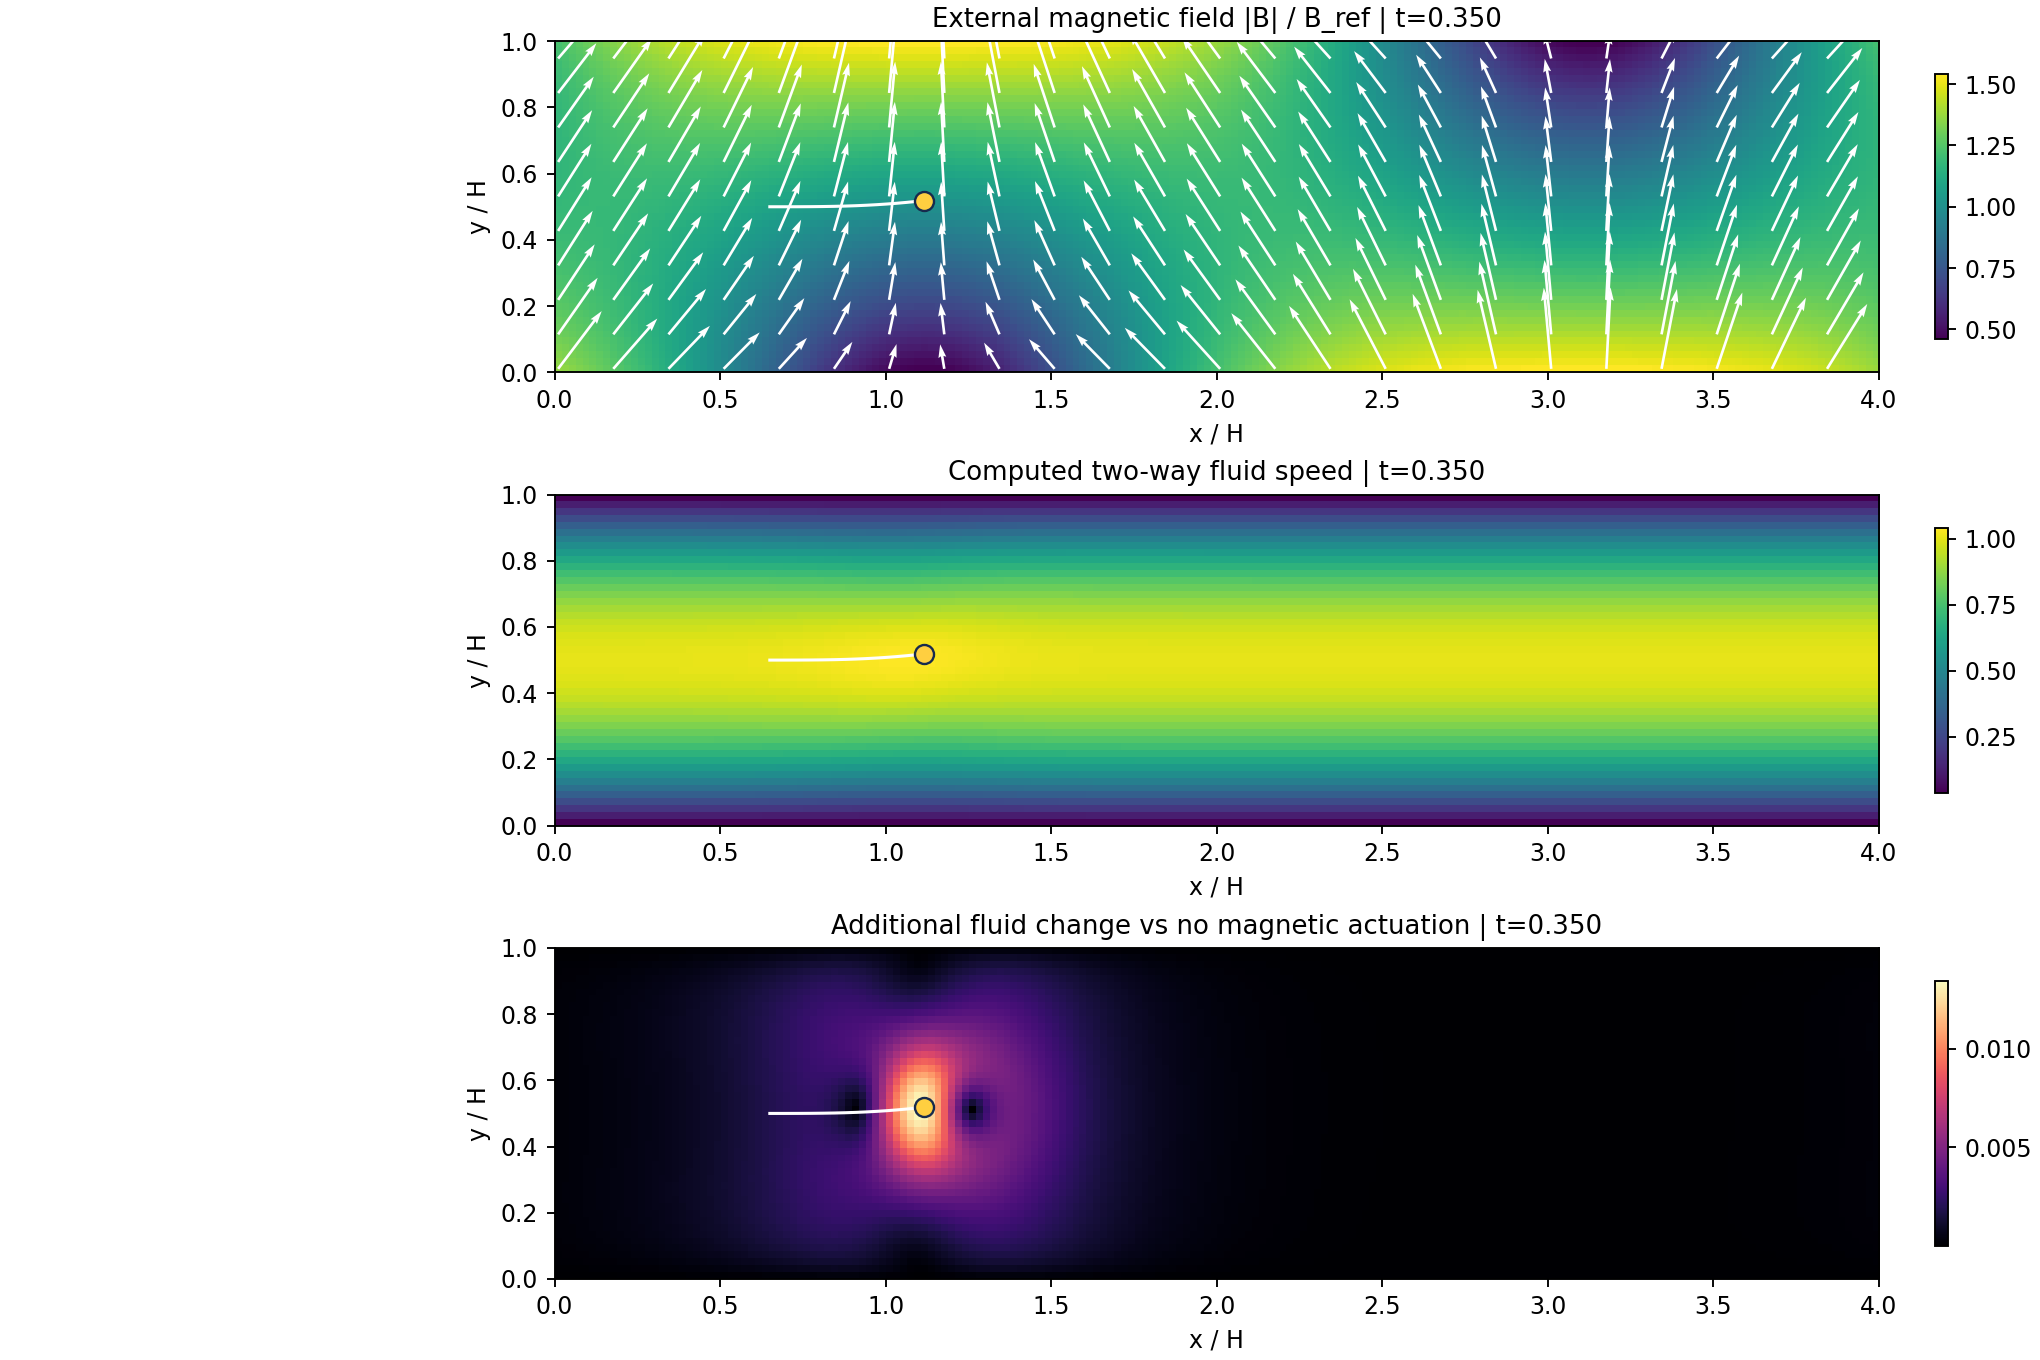

In [7]:
from IPython.display import display, HTML, Image as DisplayImage, FileLink
plot_magnetic_results(cases, selected, report, OUT)
for name in ['magnetic_control_and_audit.png','magnetic_field_and_fluid.png']:
    display(DisplayImage(filename=str(OUT/name)))

## ۸. انیمیشن آفلاین — پخش، توقف و انتخاب زمان

Animation: 61 frames; rendered in 43.7s



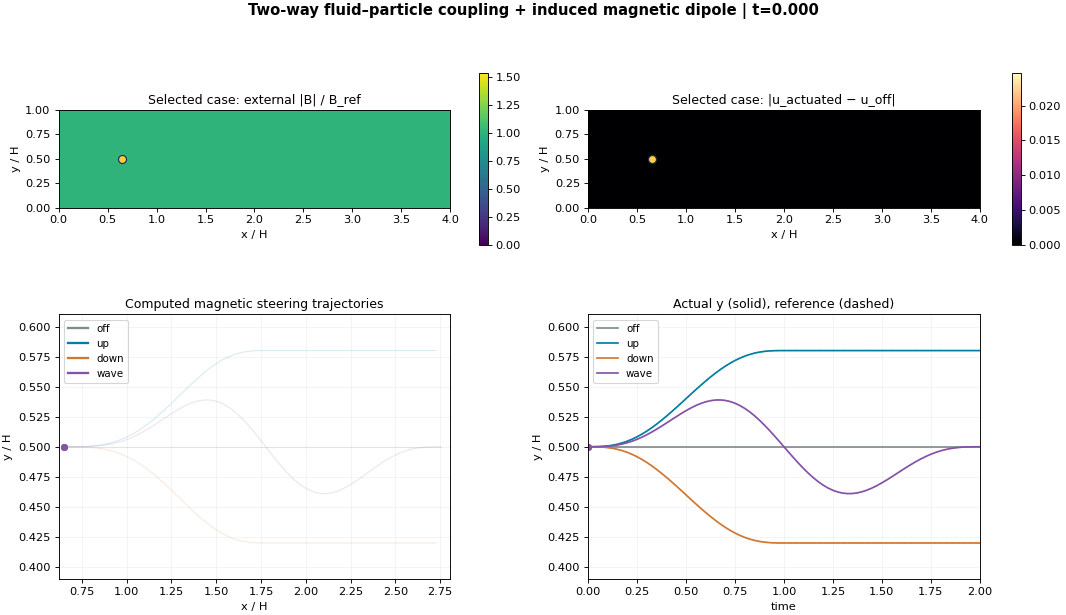
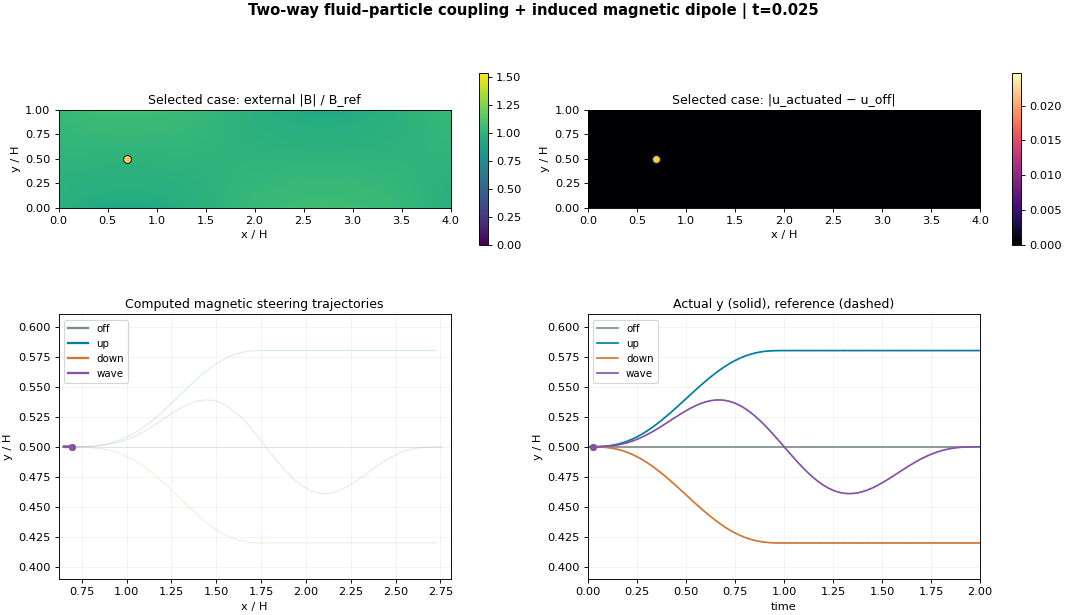
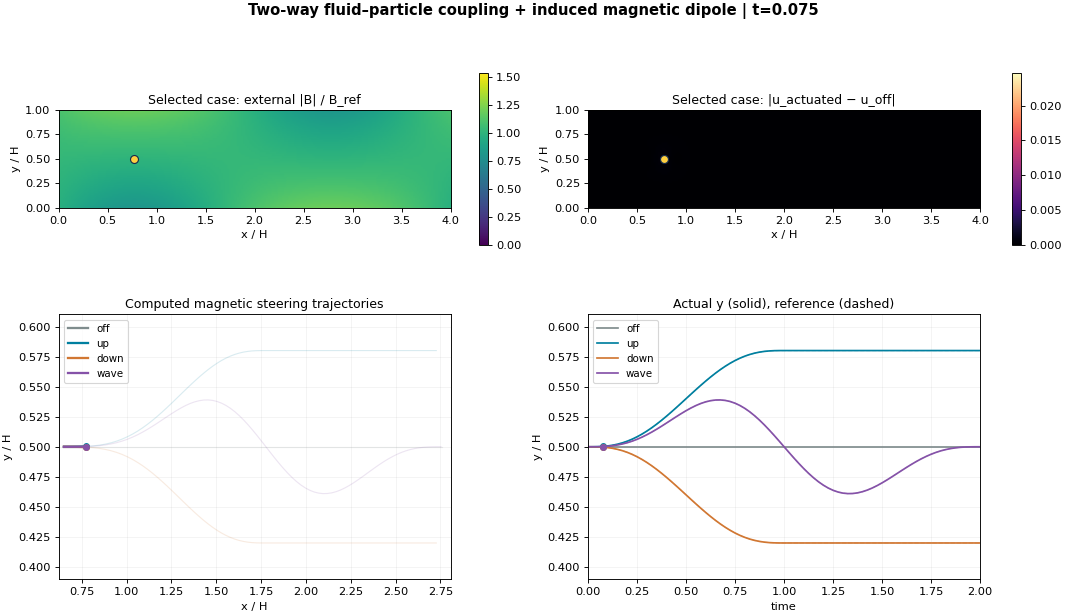
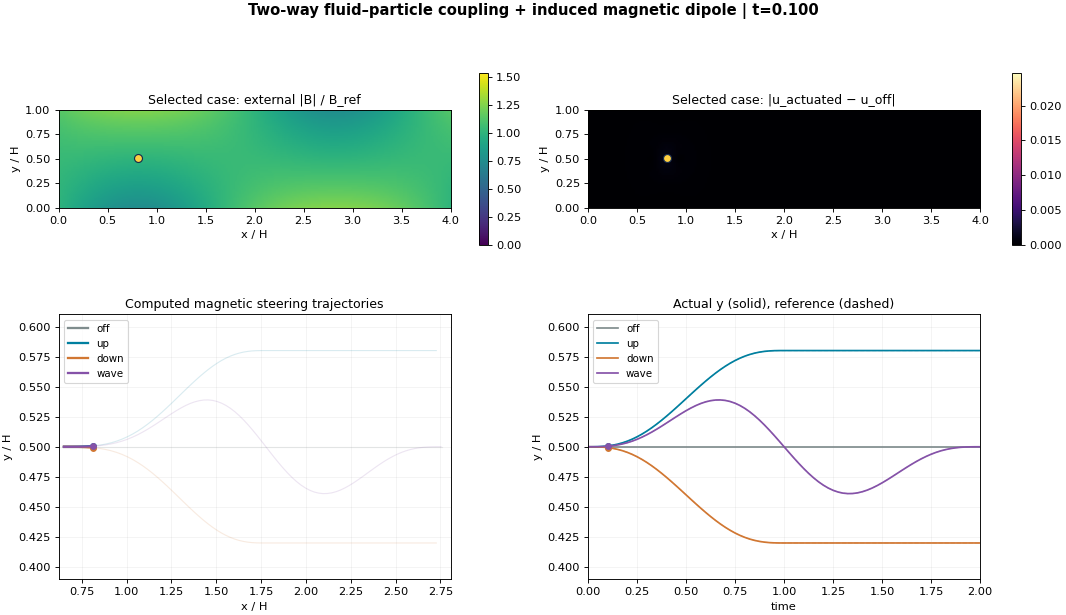
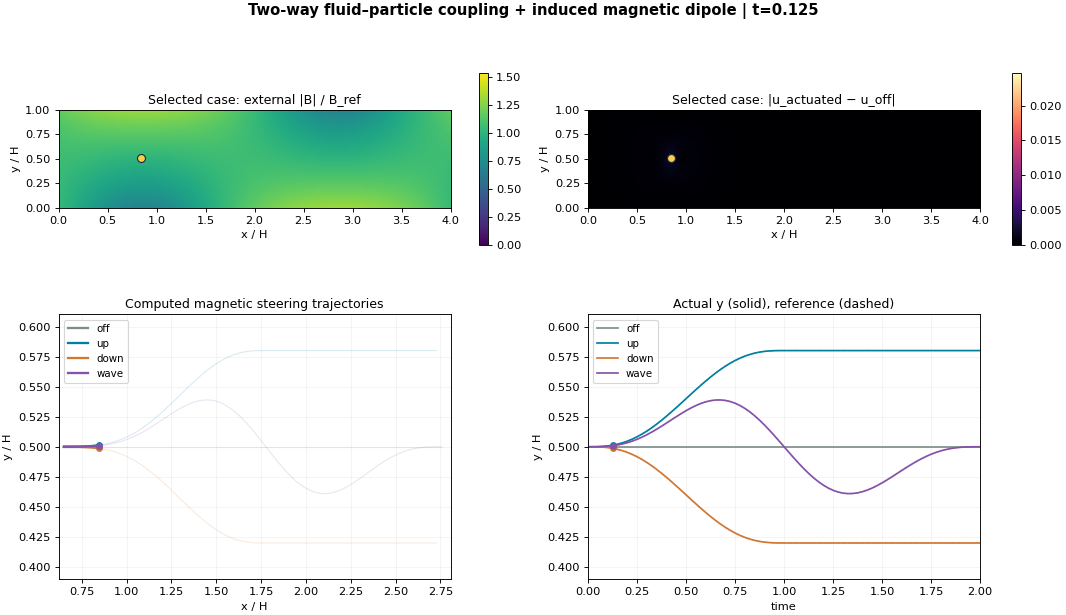
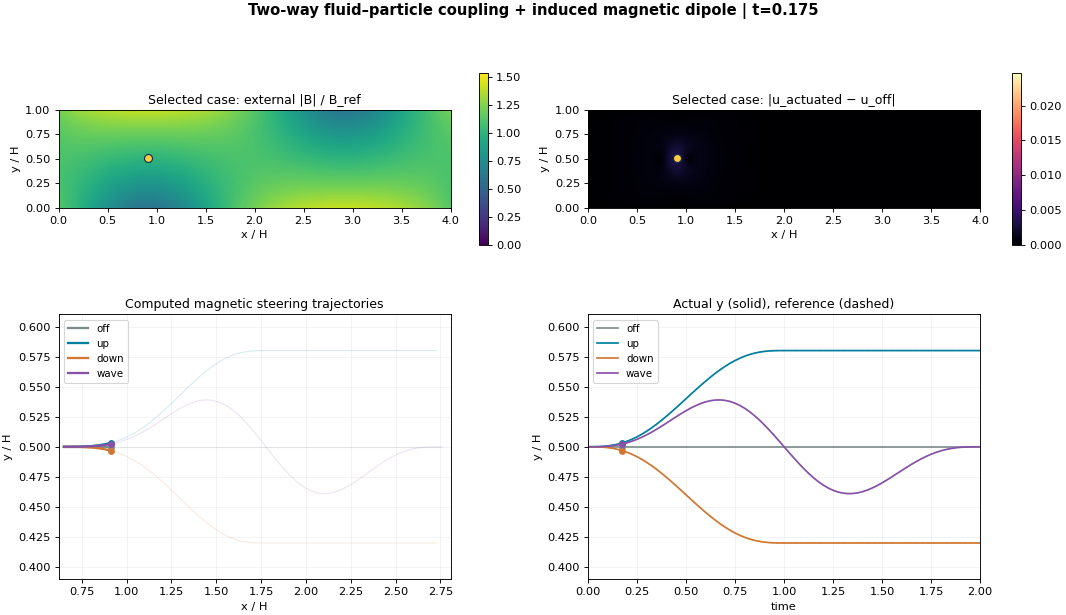
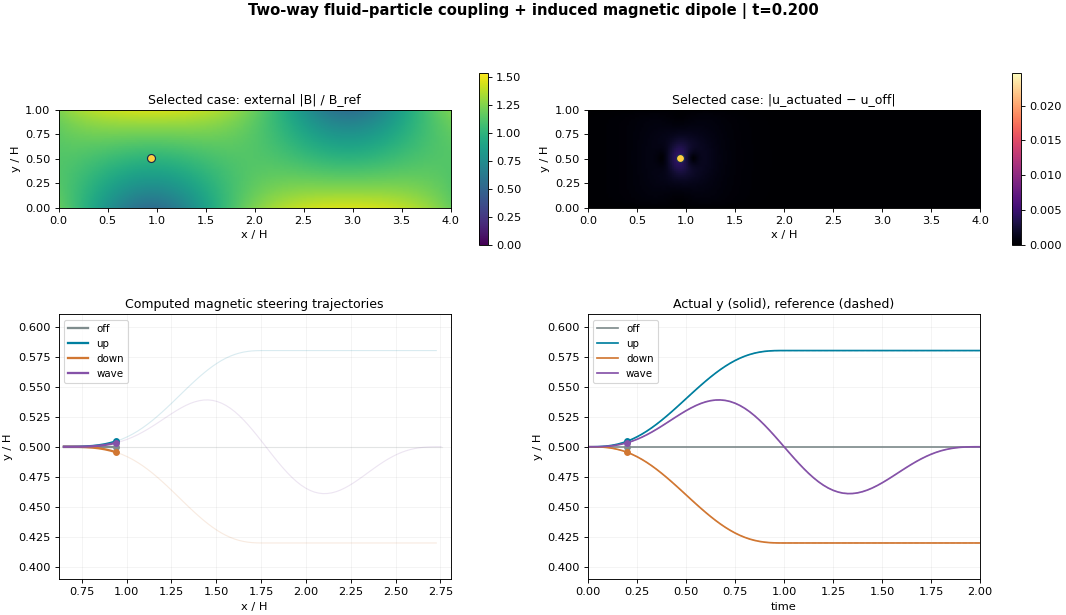
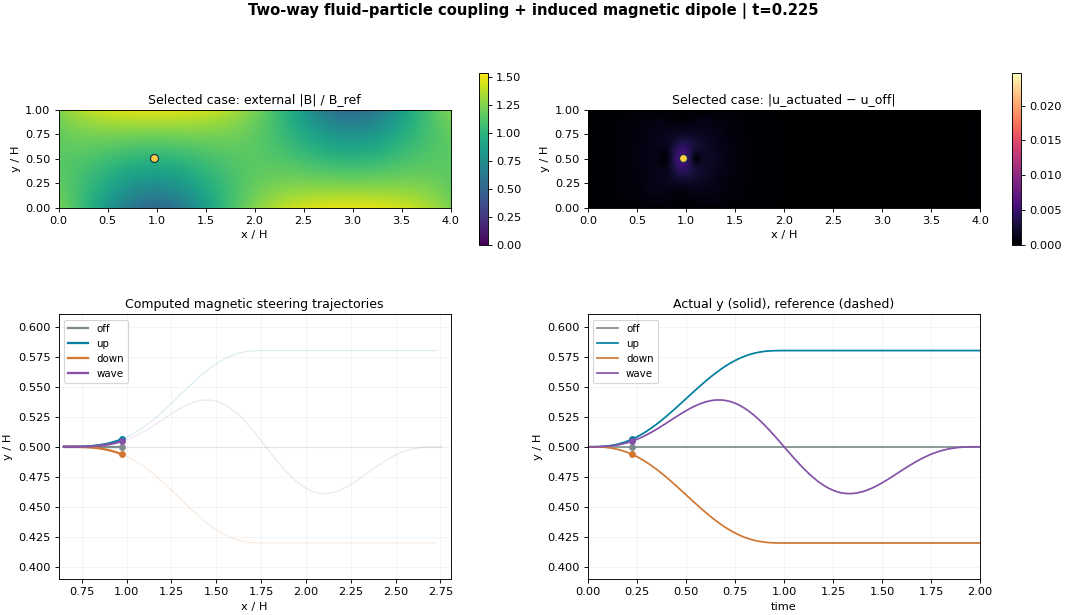
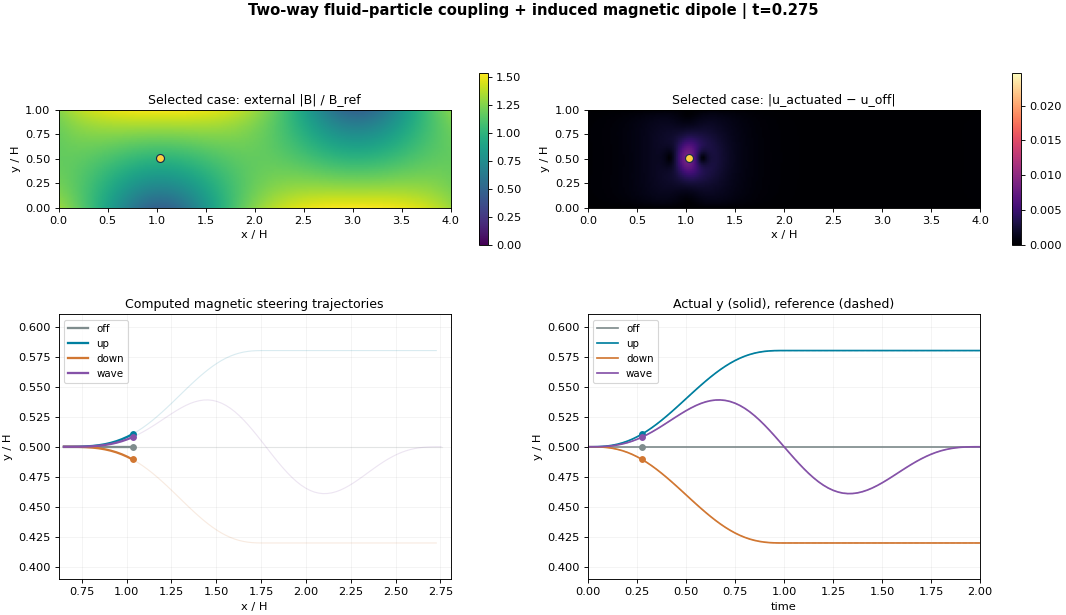
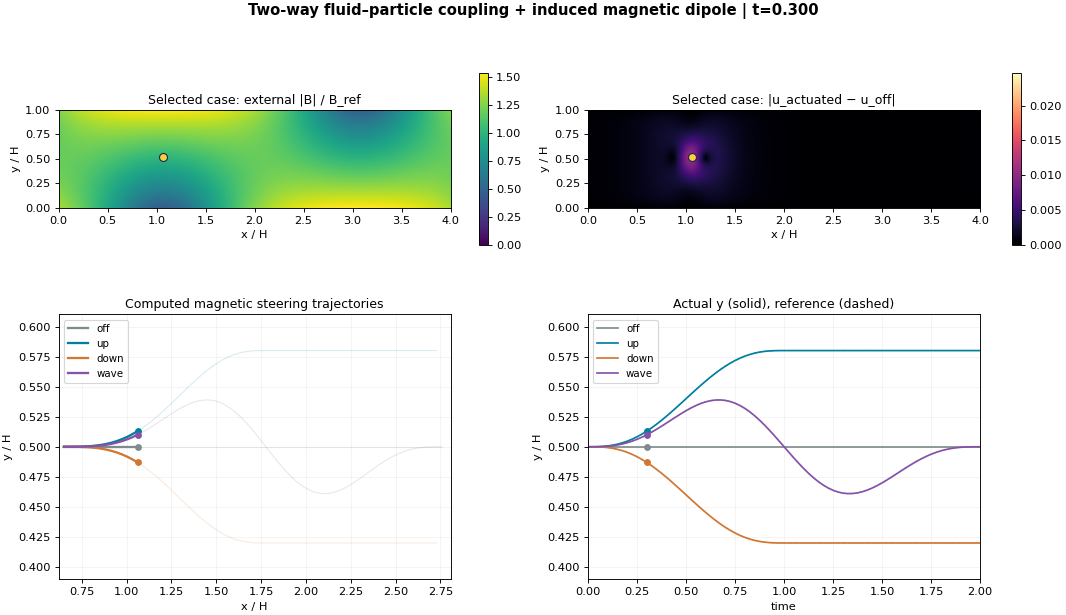
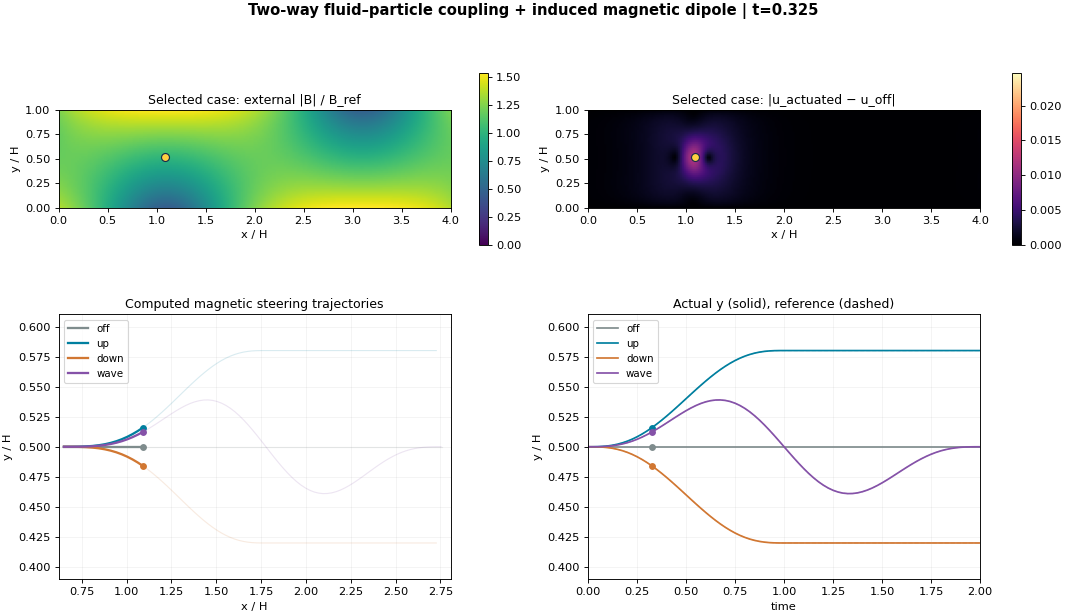
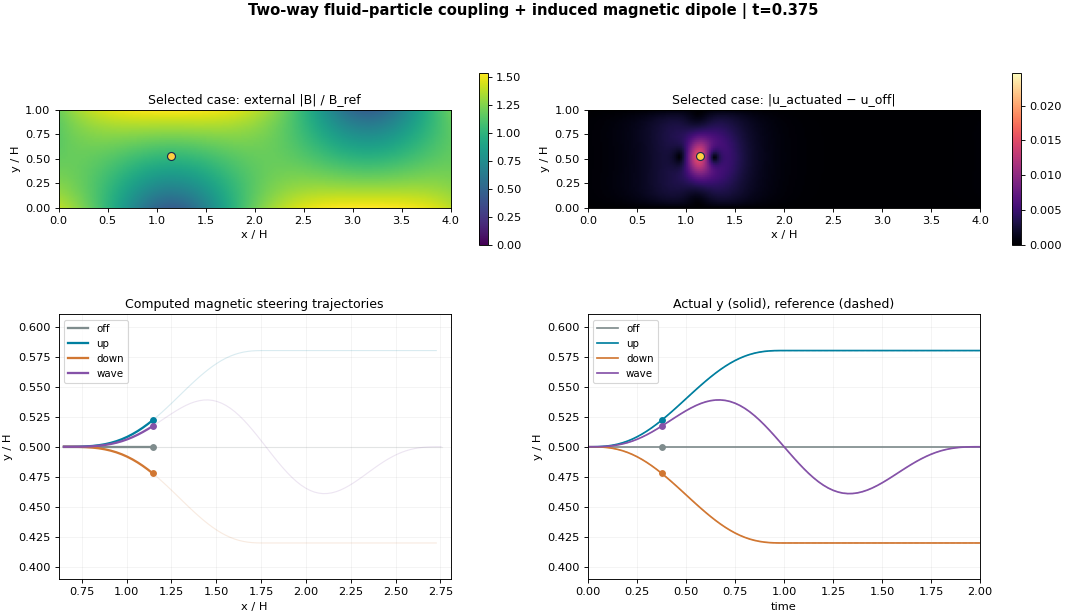
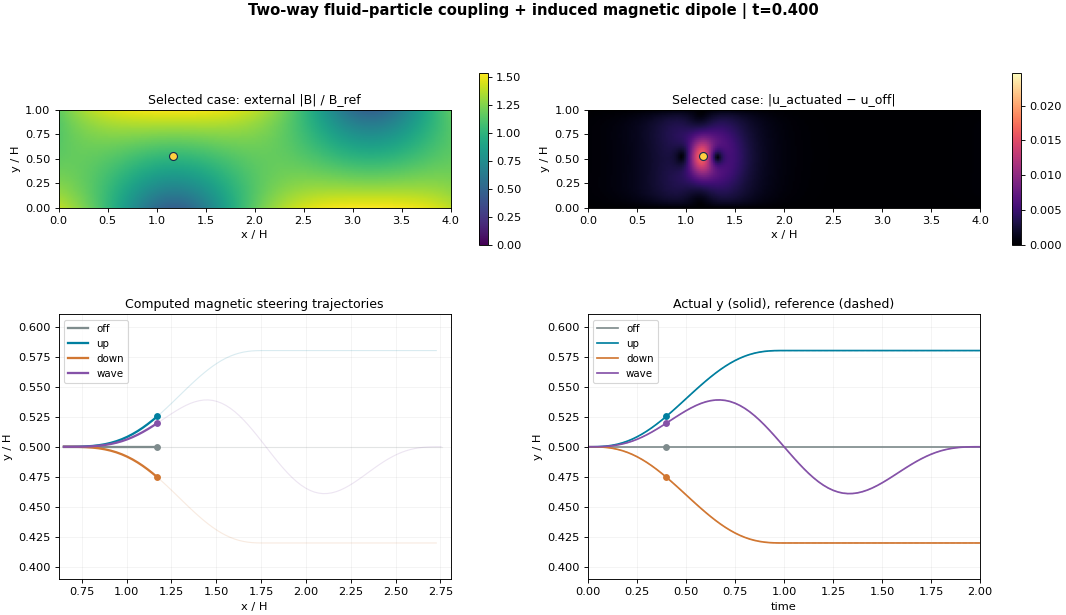
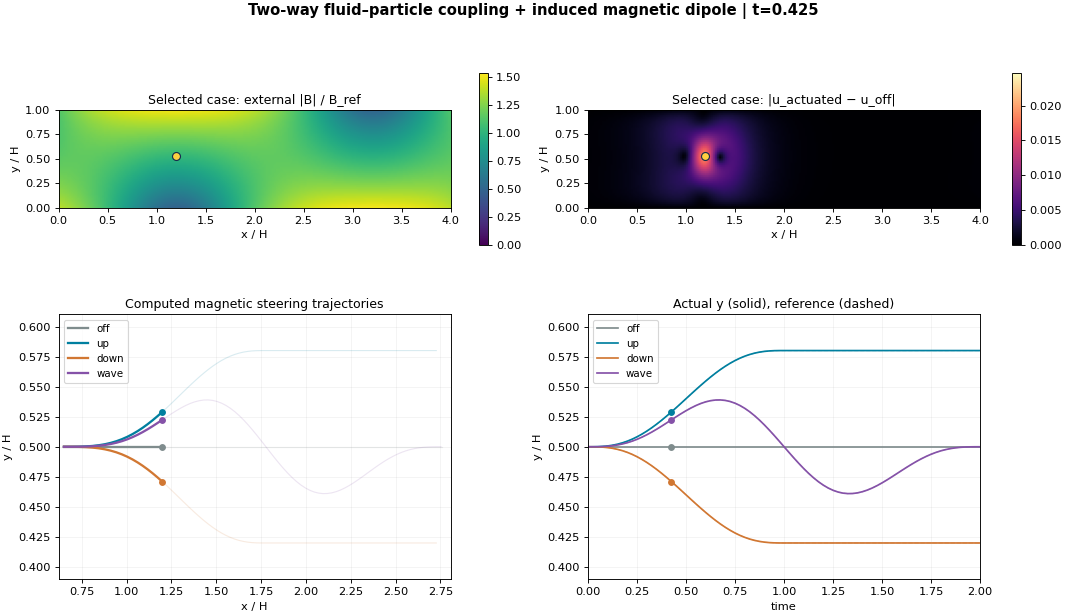
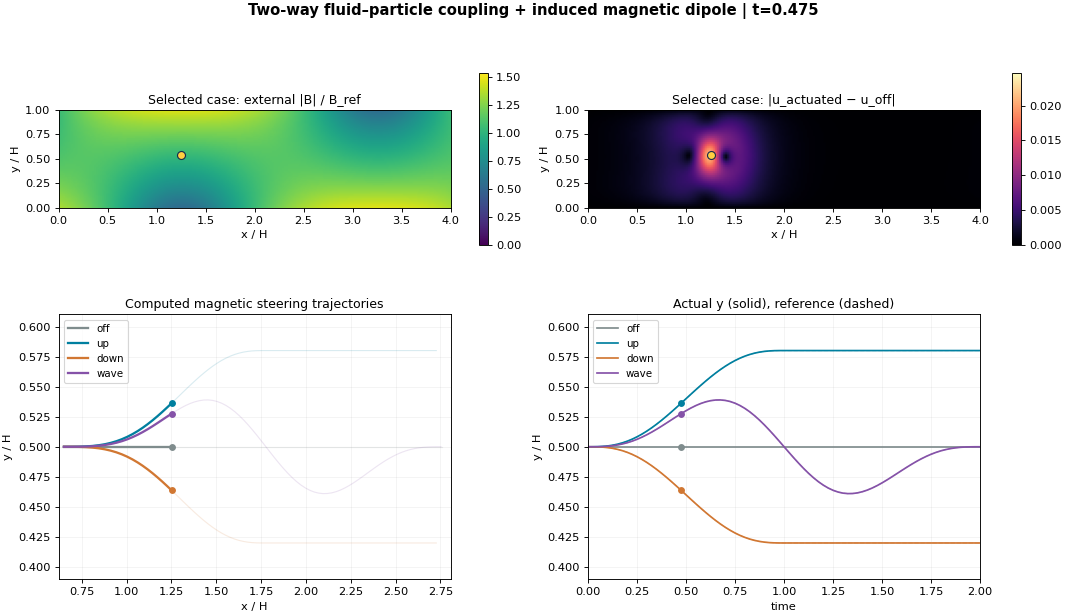
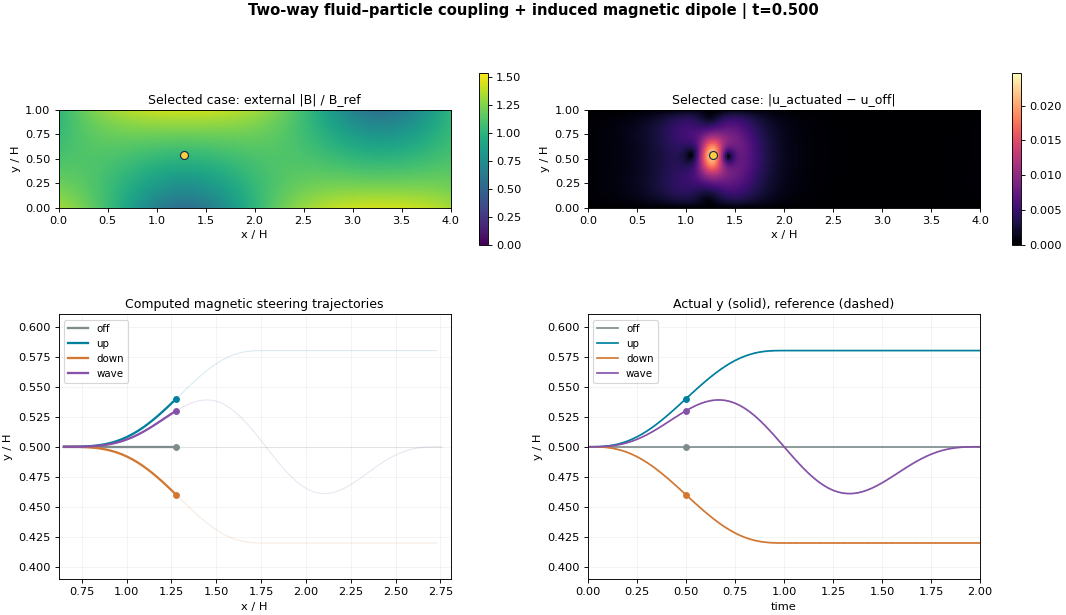
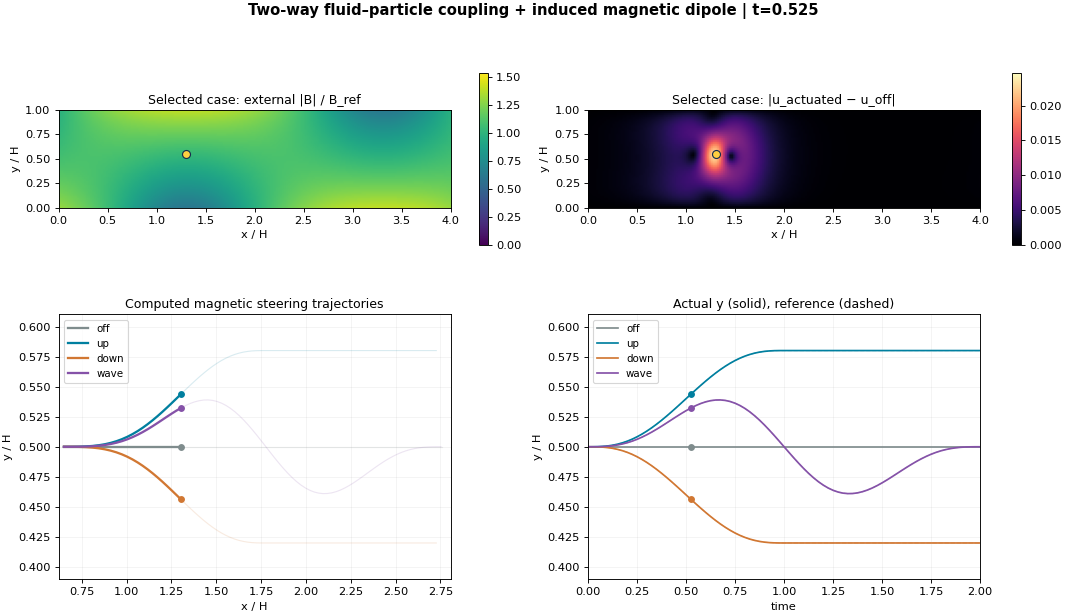
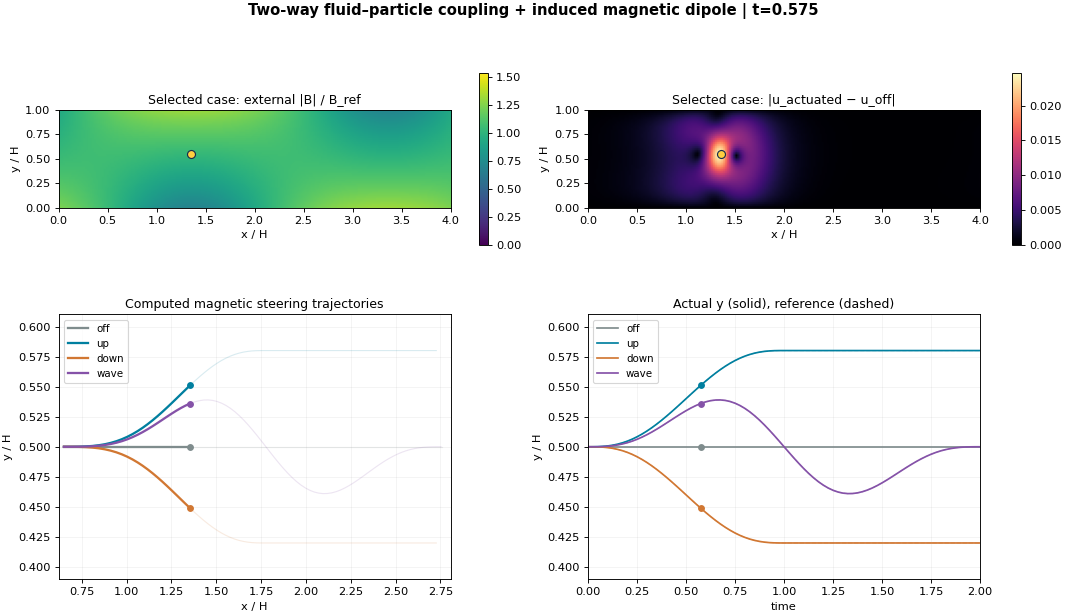
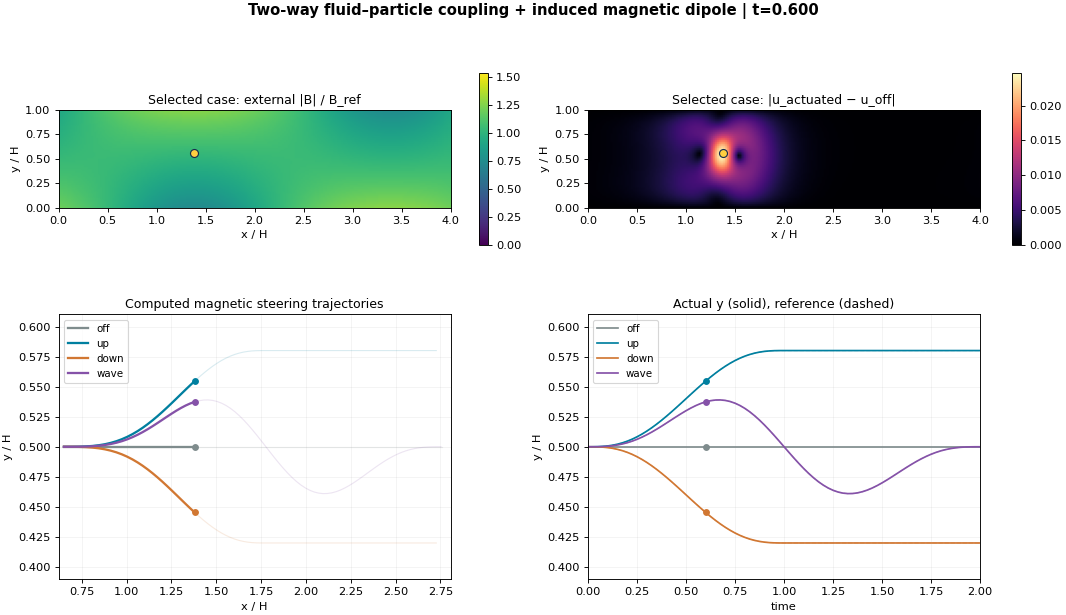
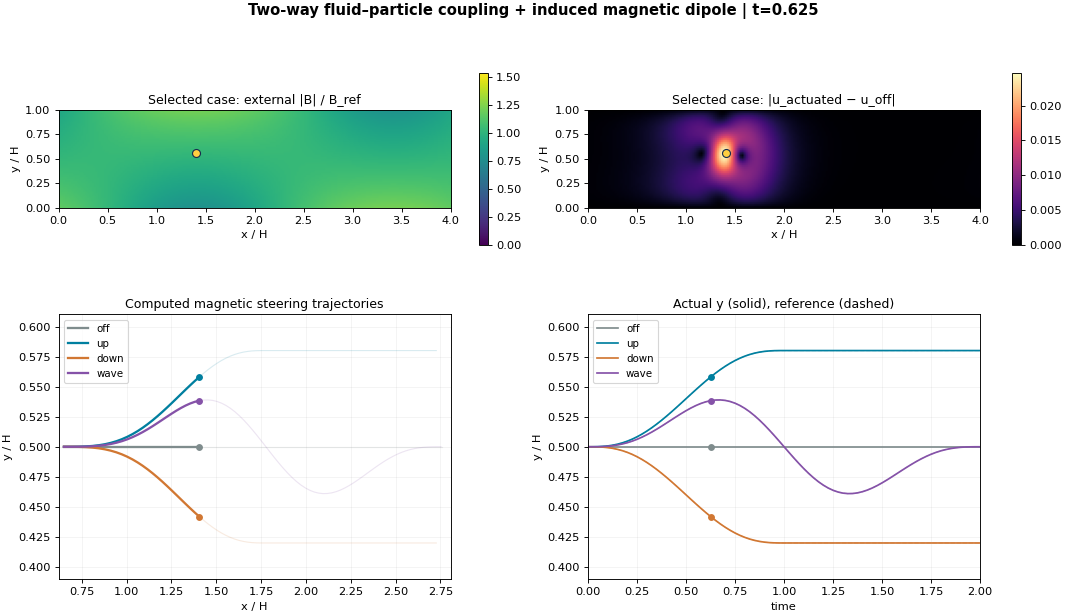
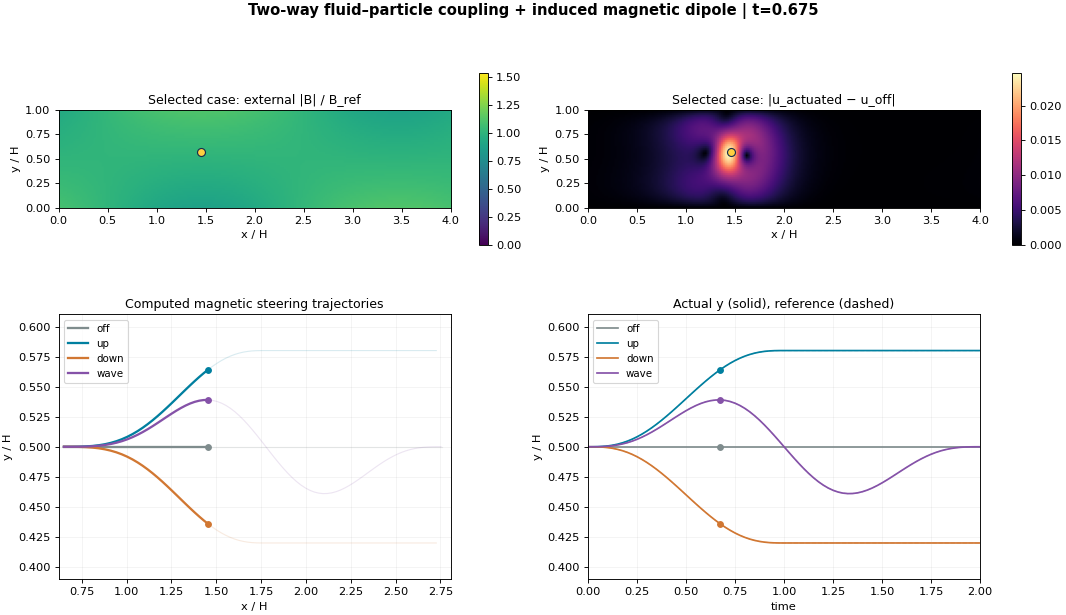
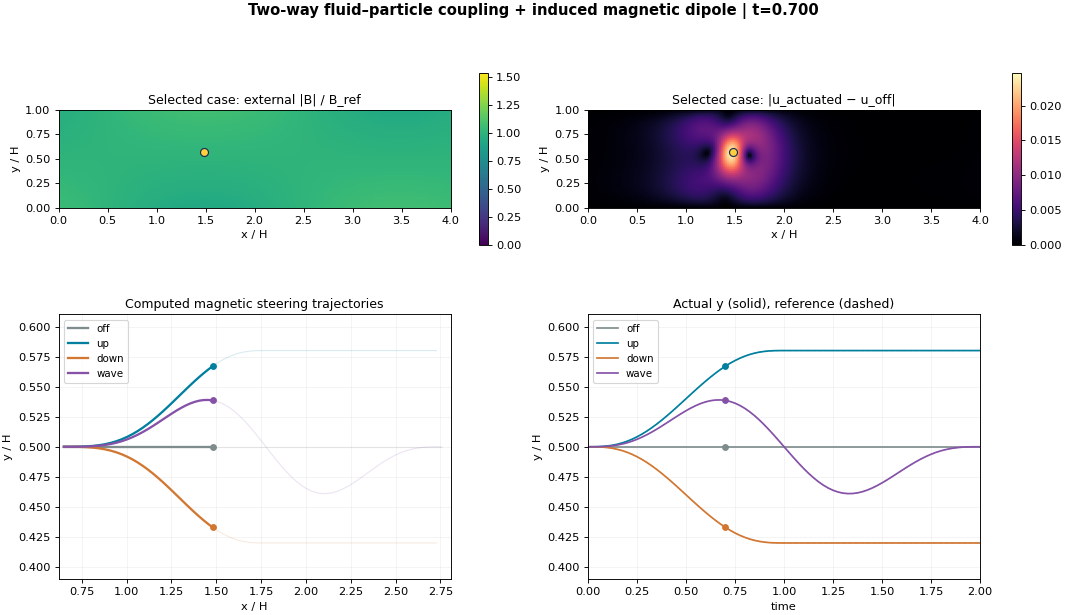
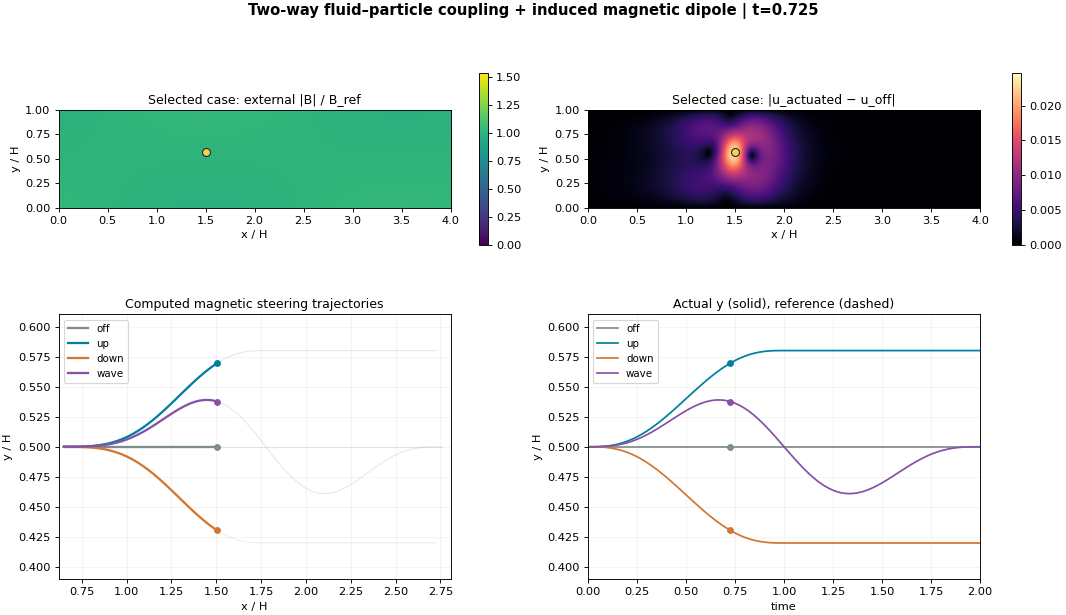
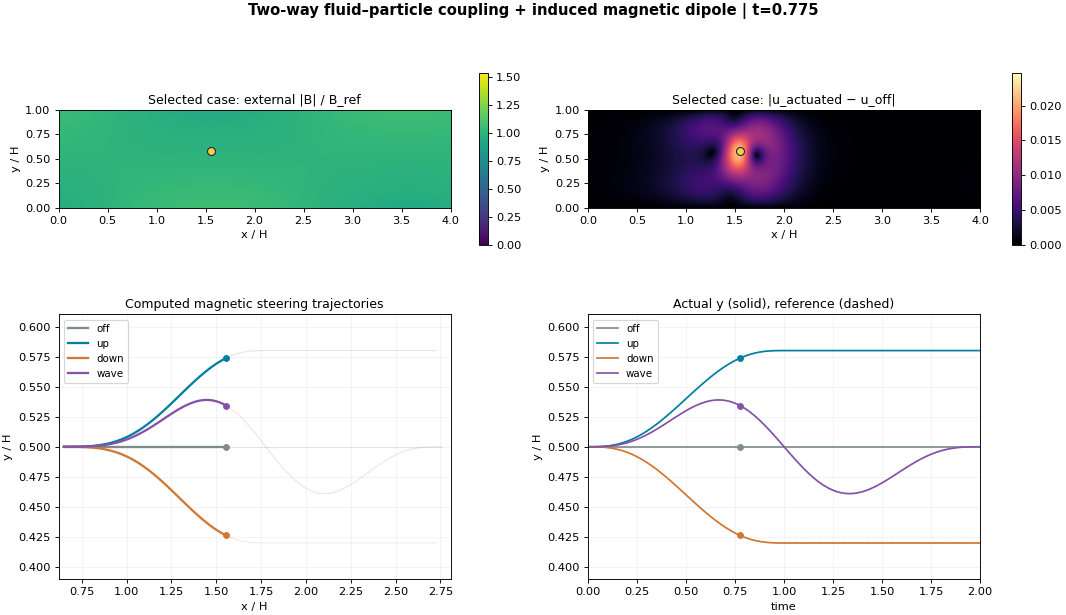
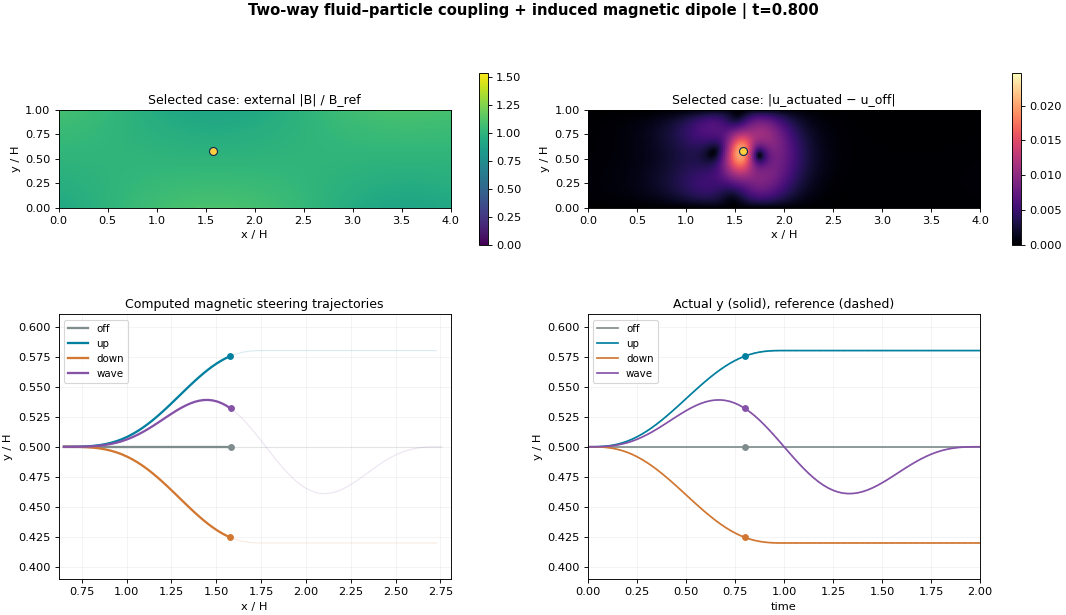
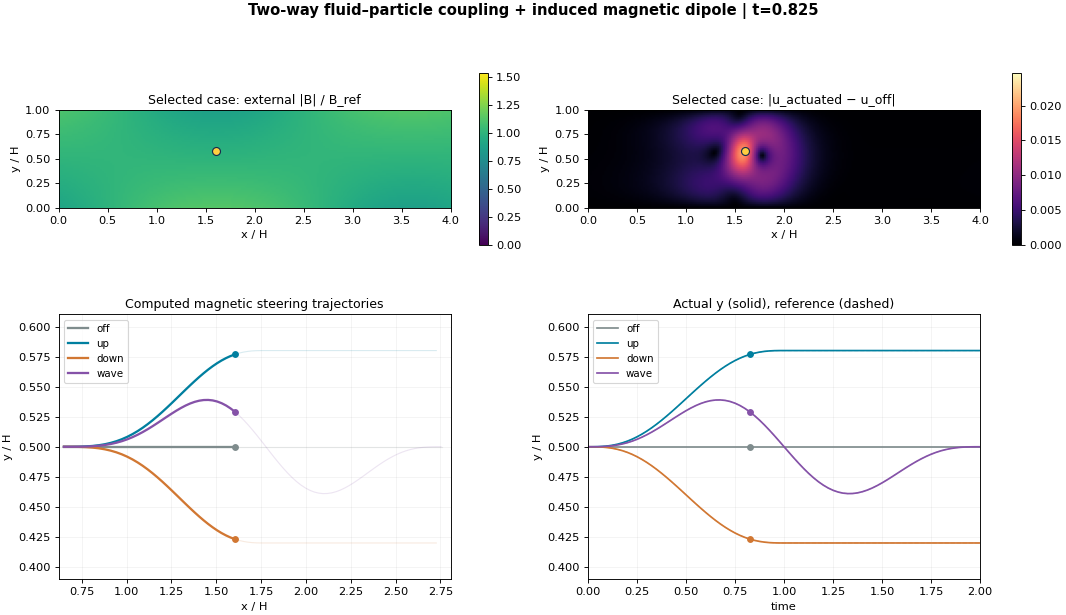
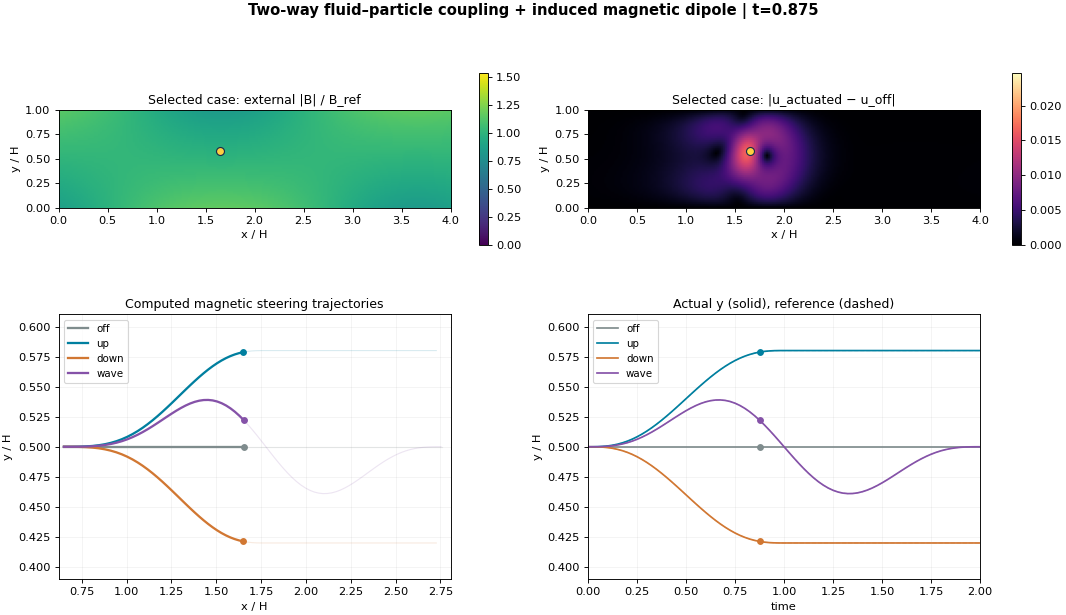
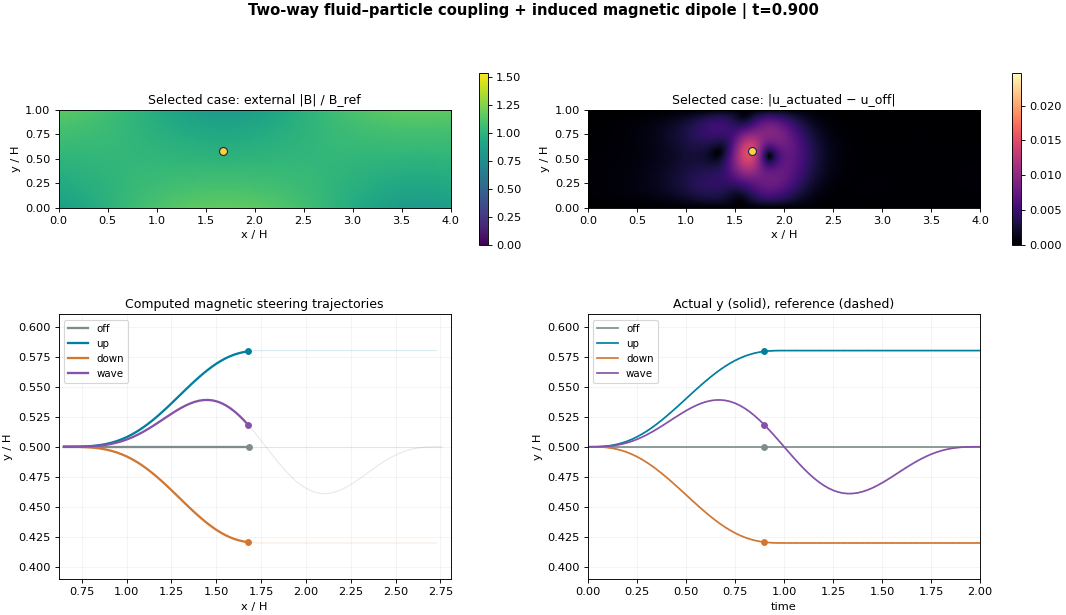
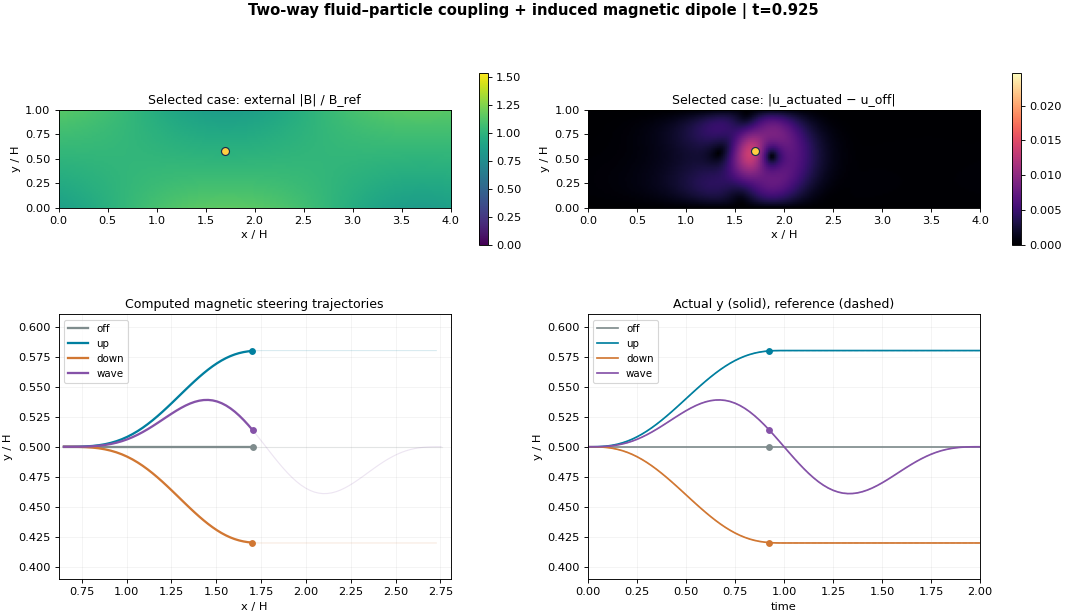
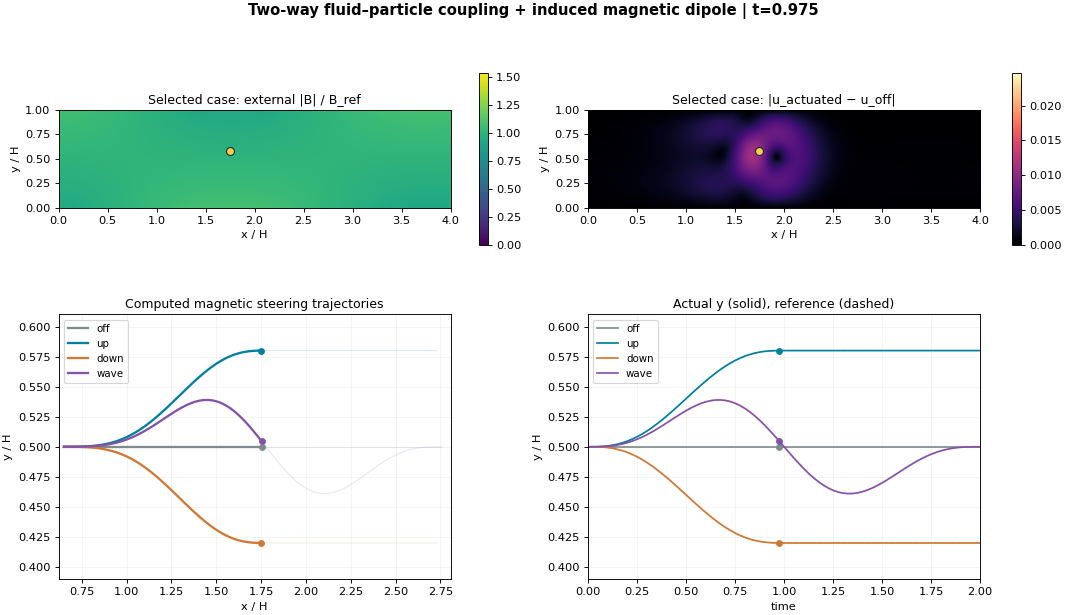
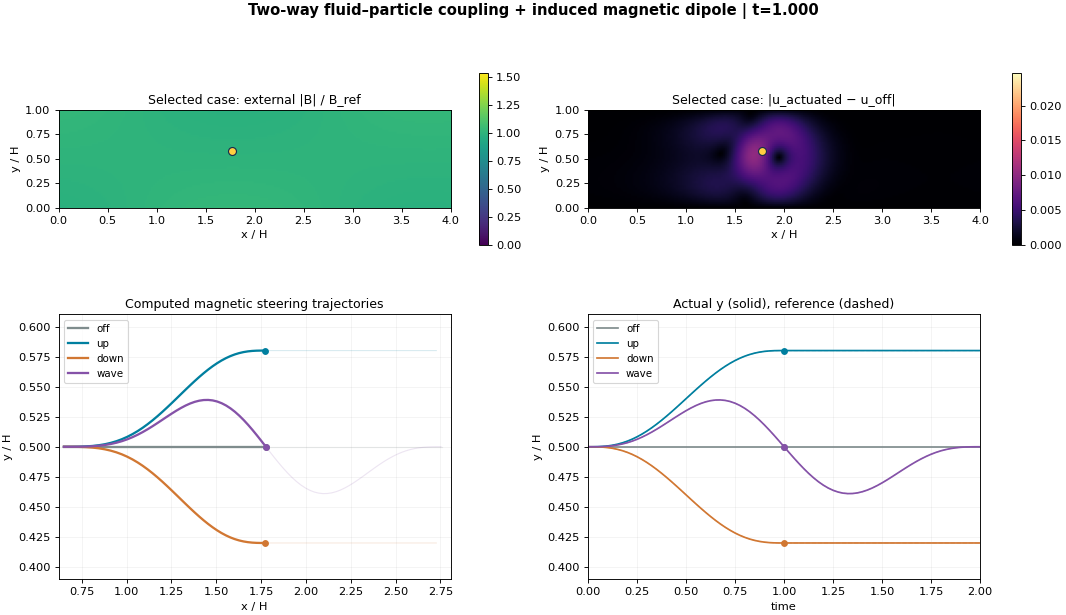
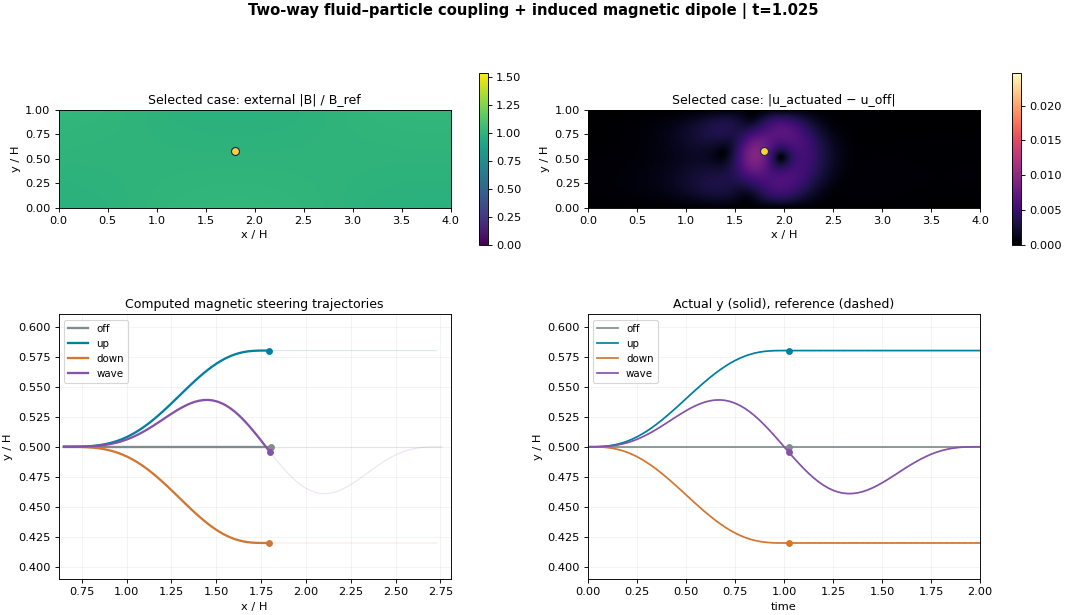
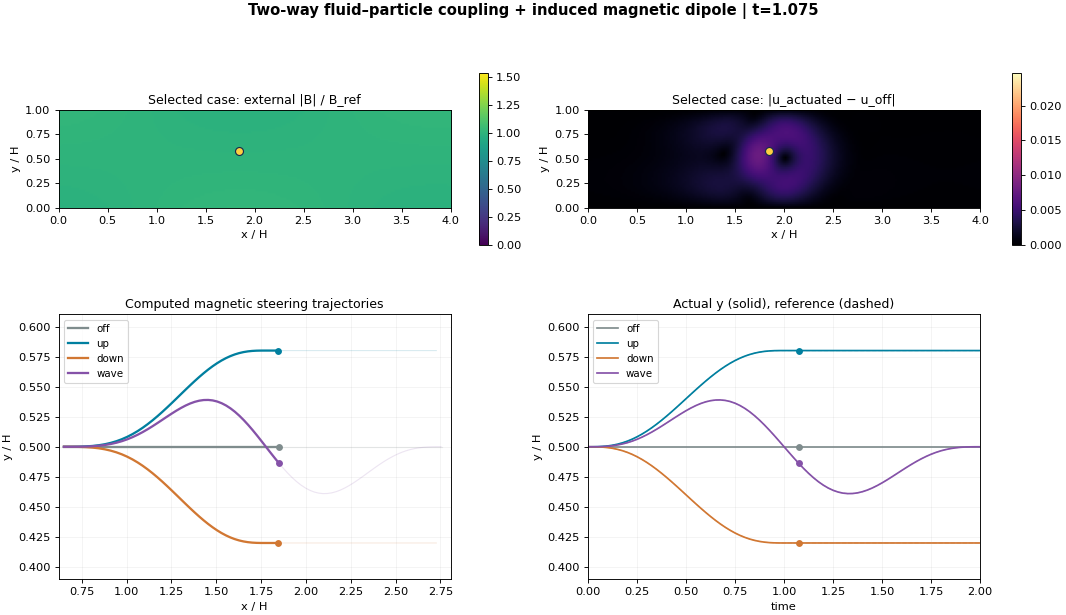
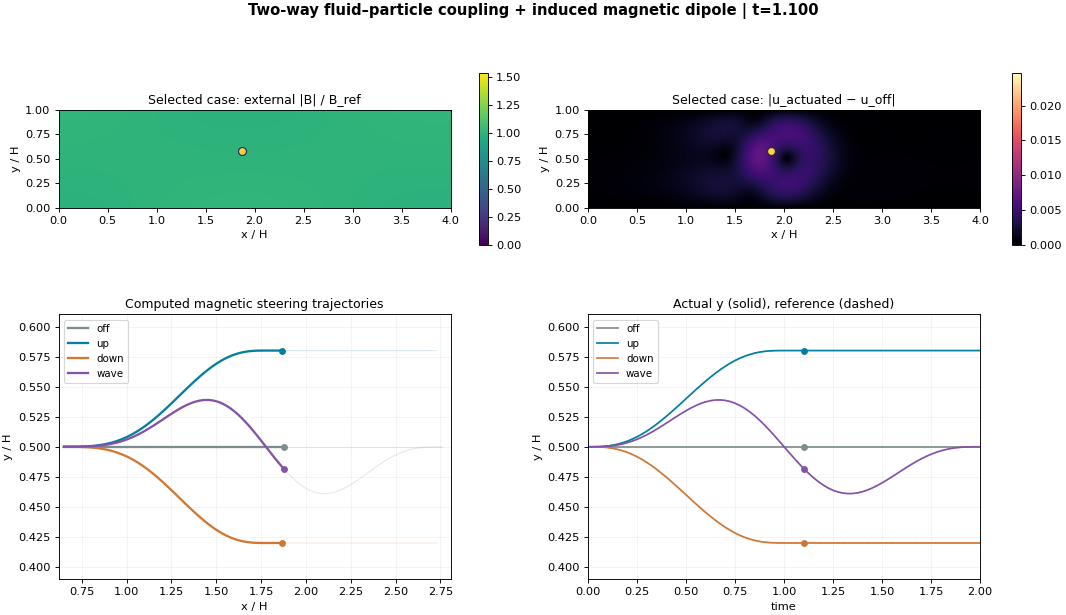
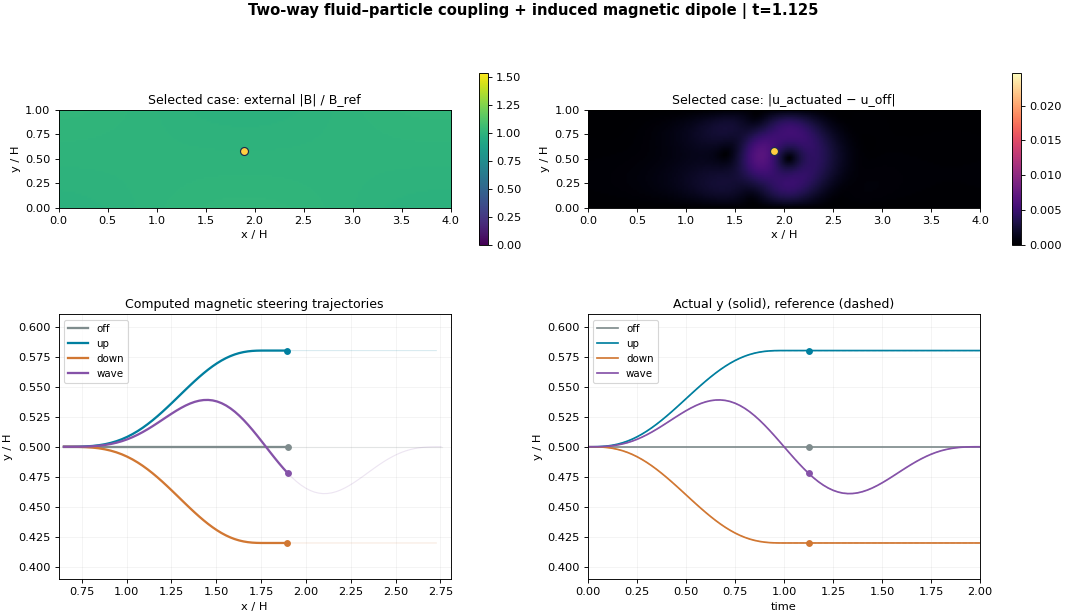
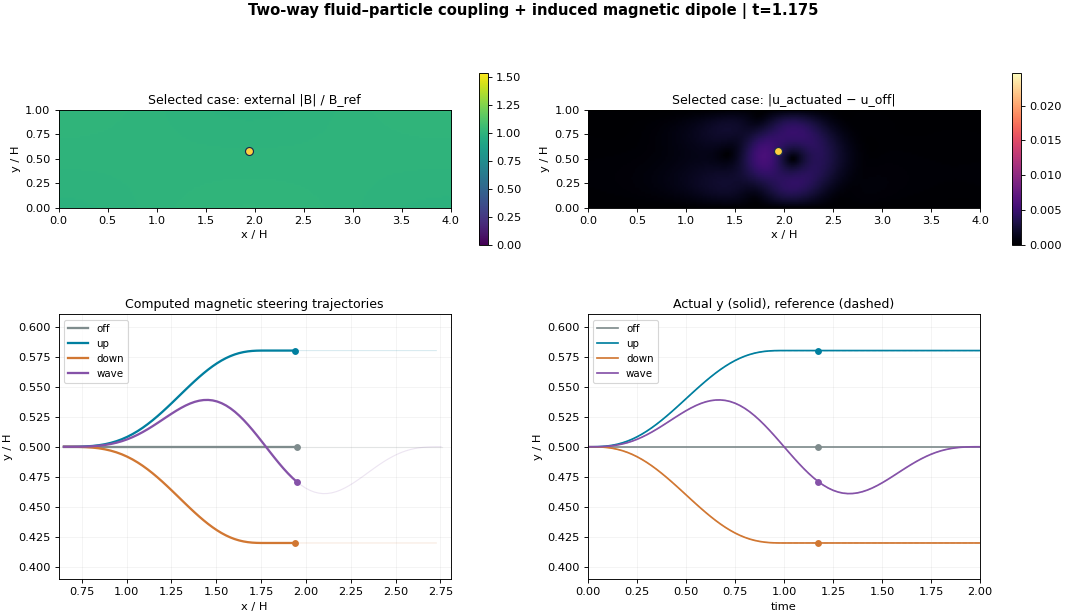
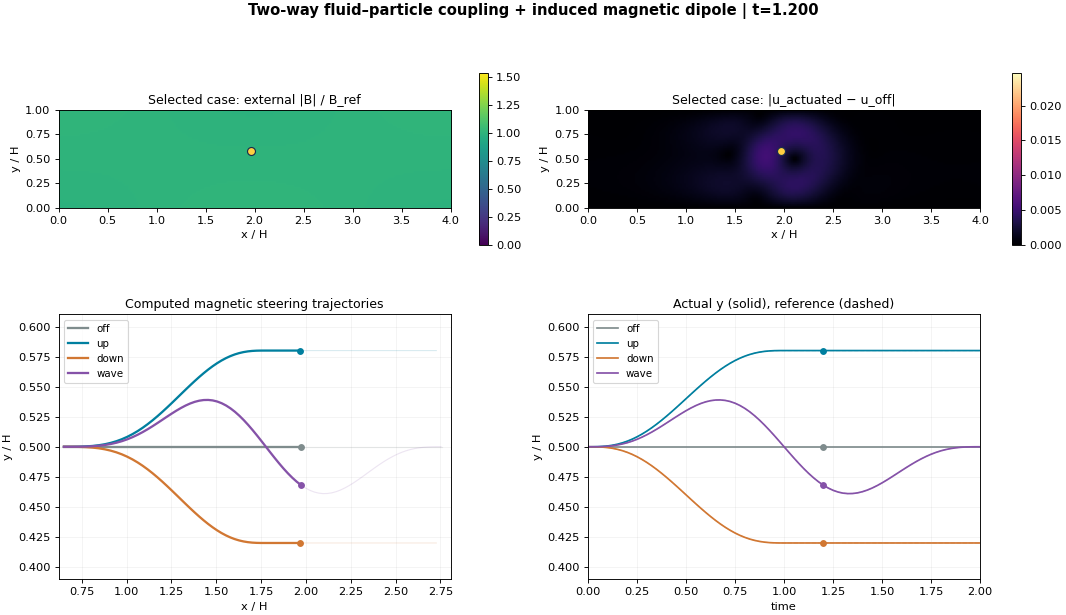
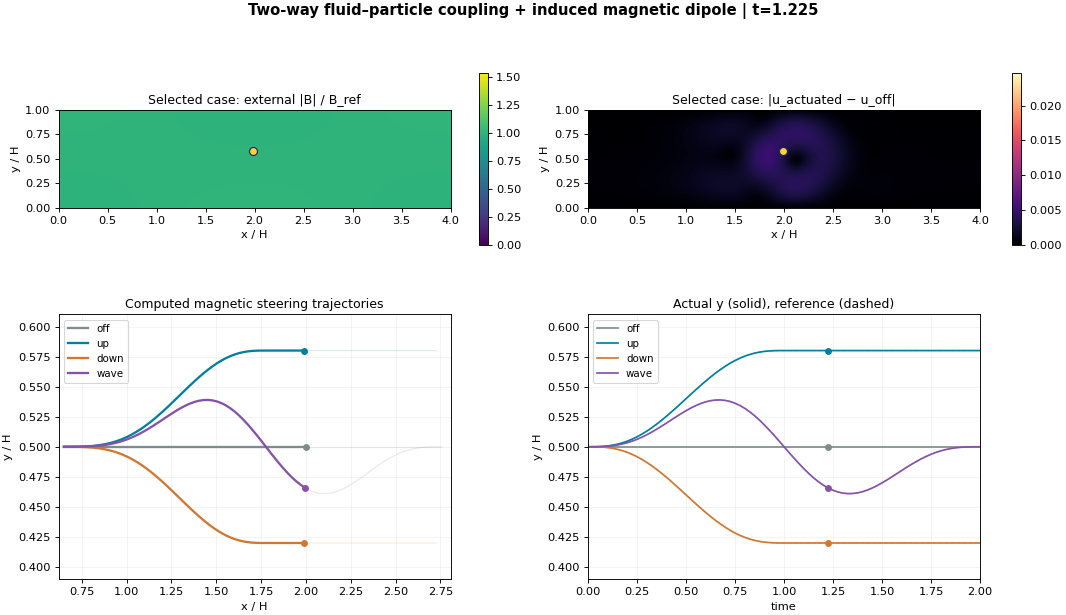
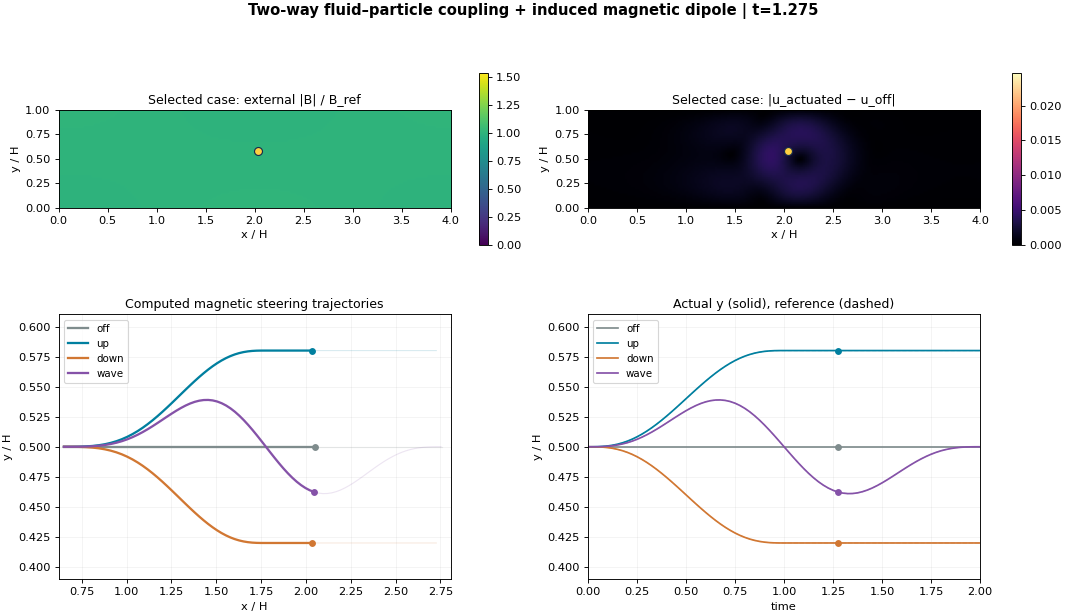
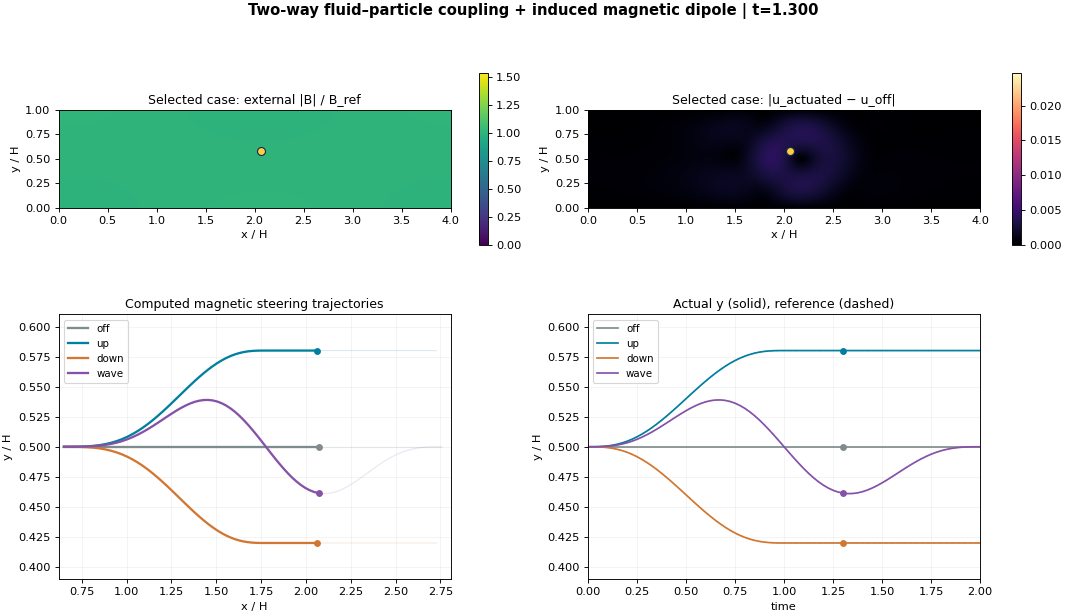
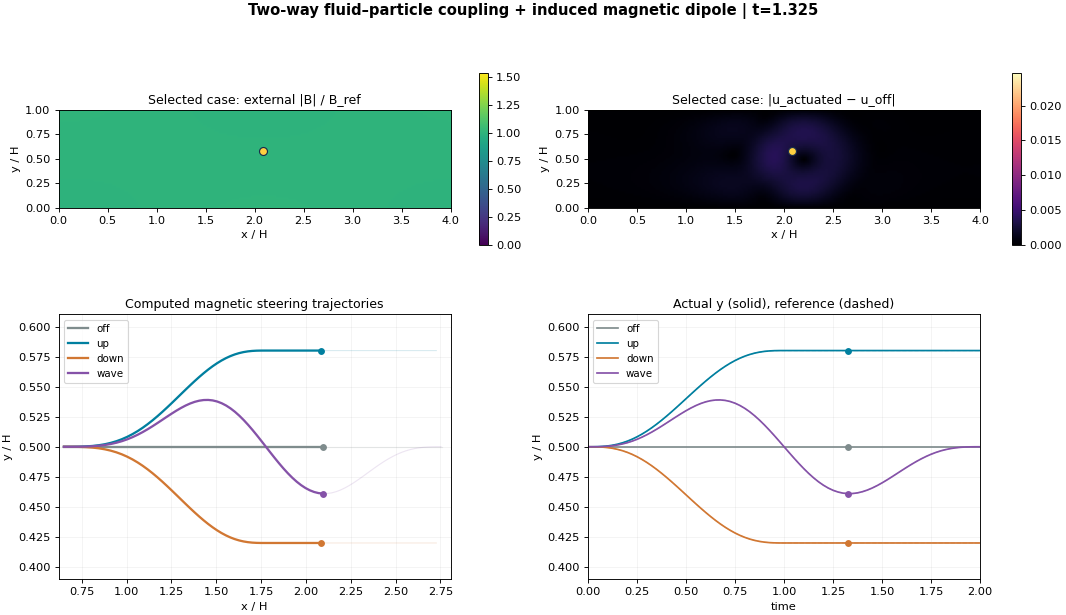
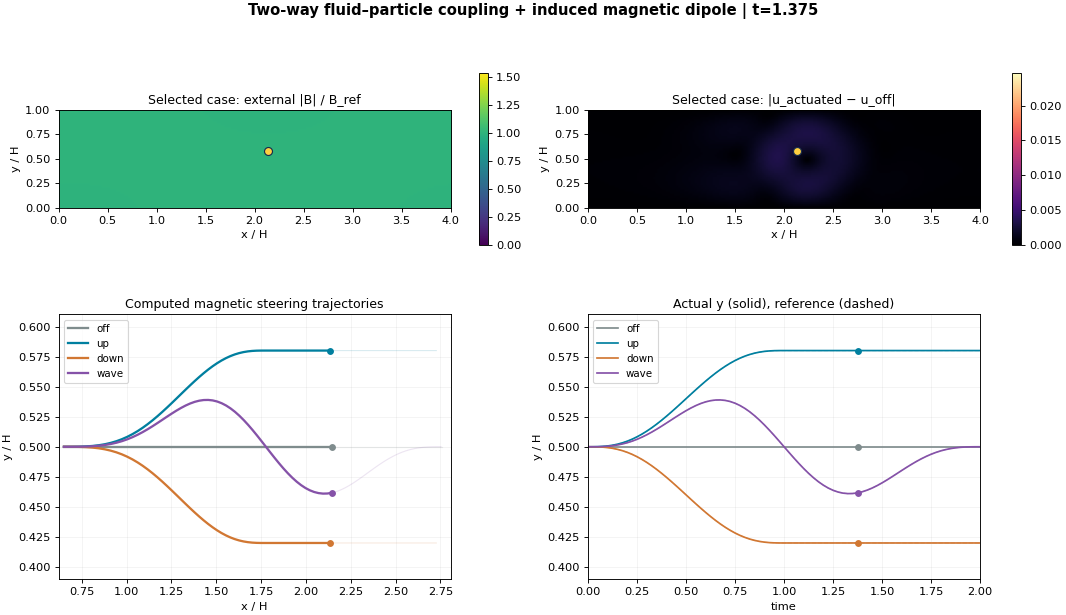
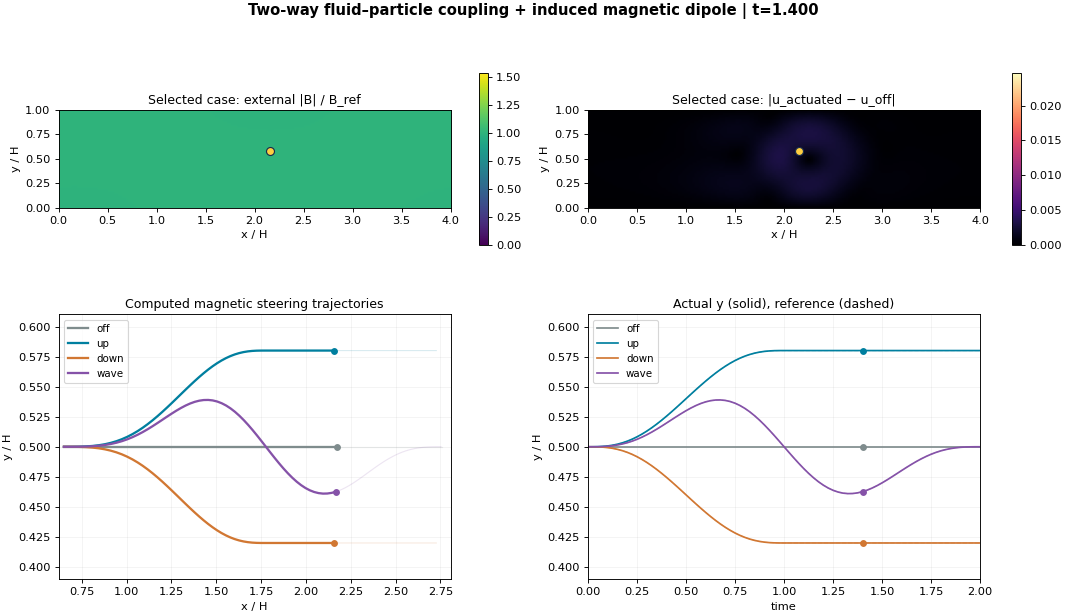
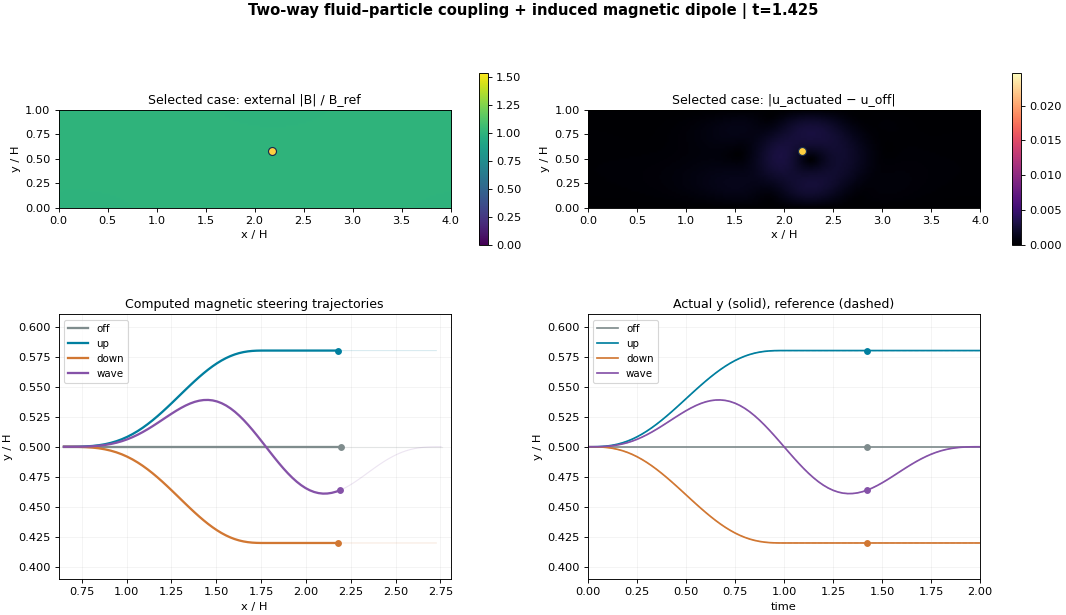
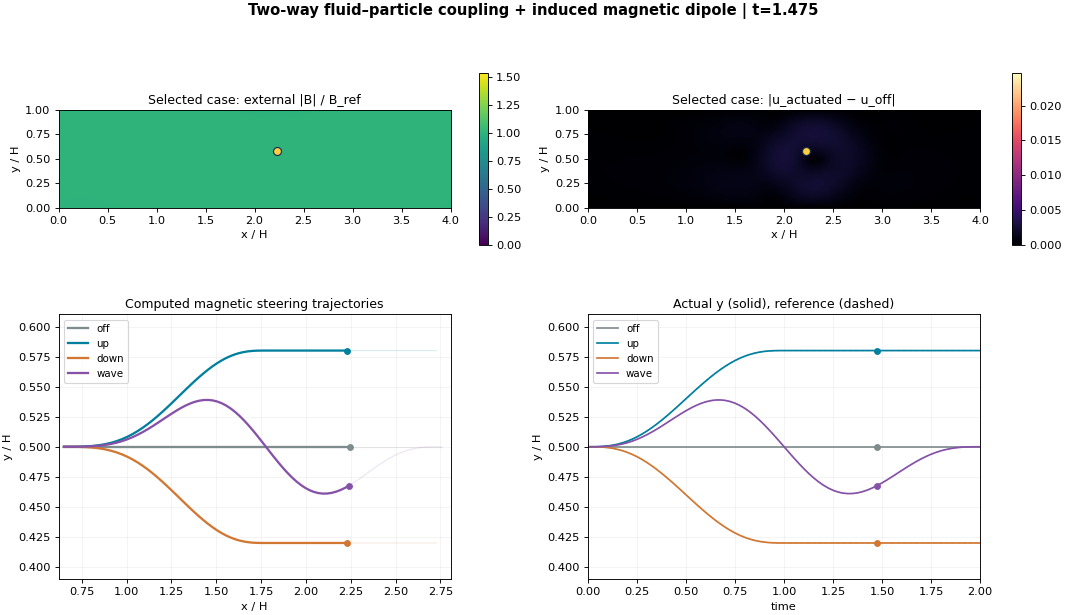
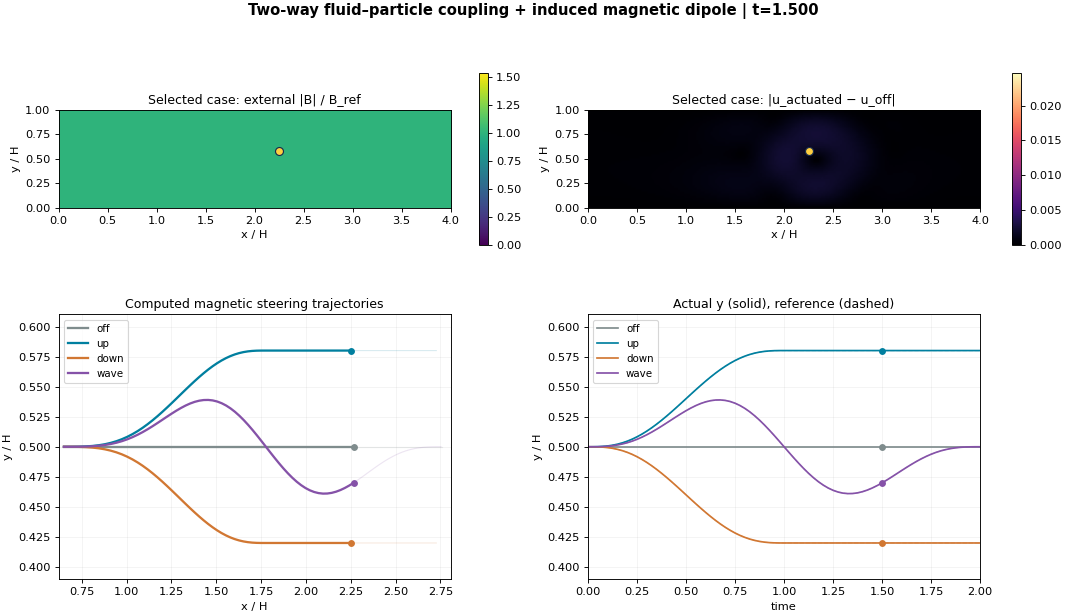
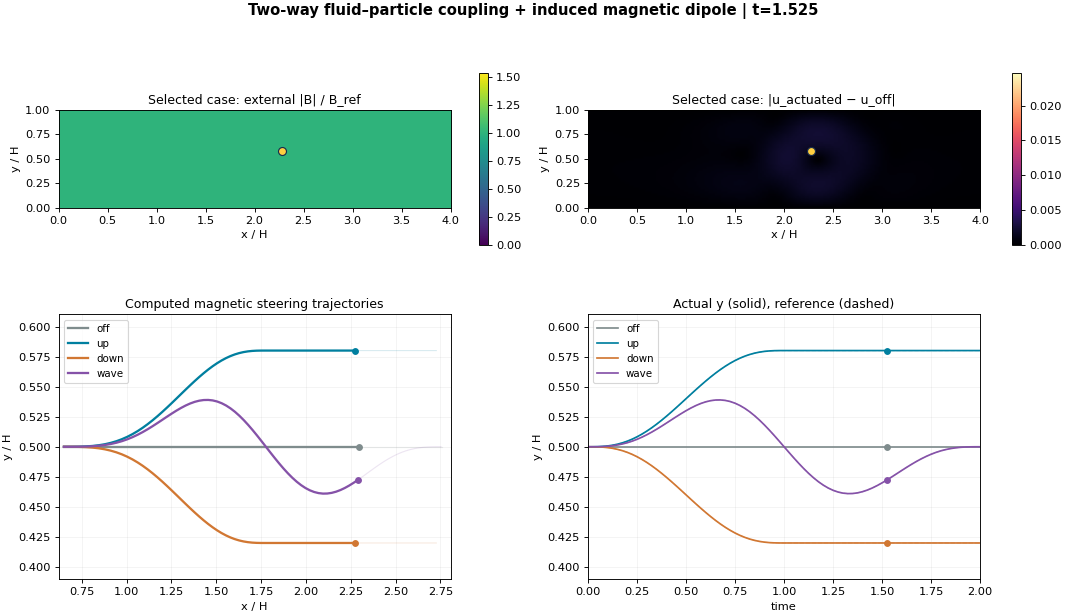
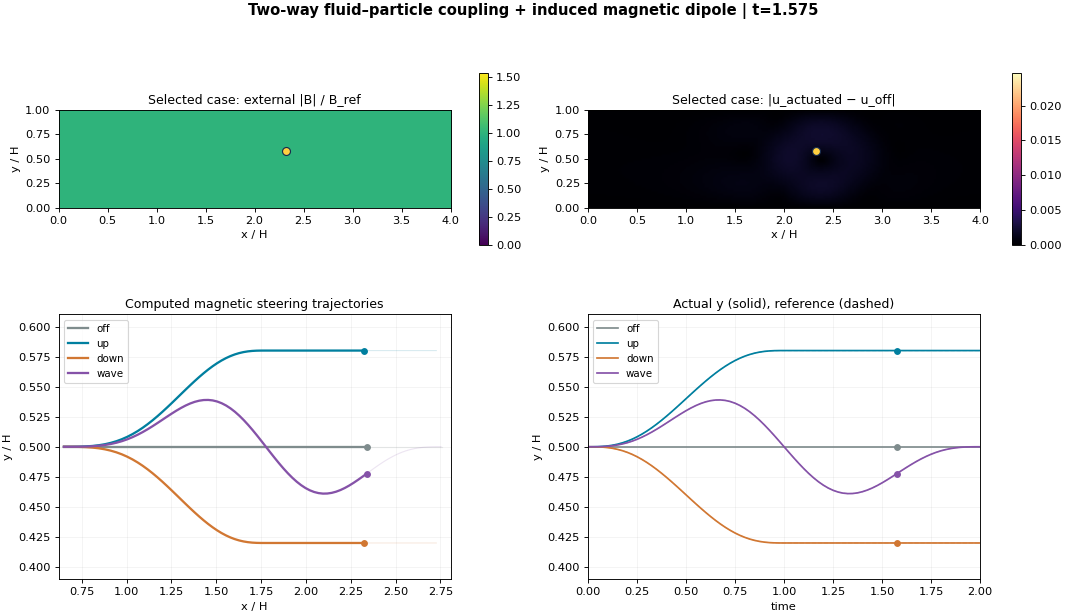
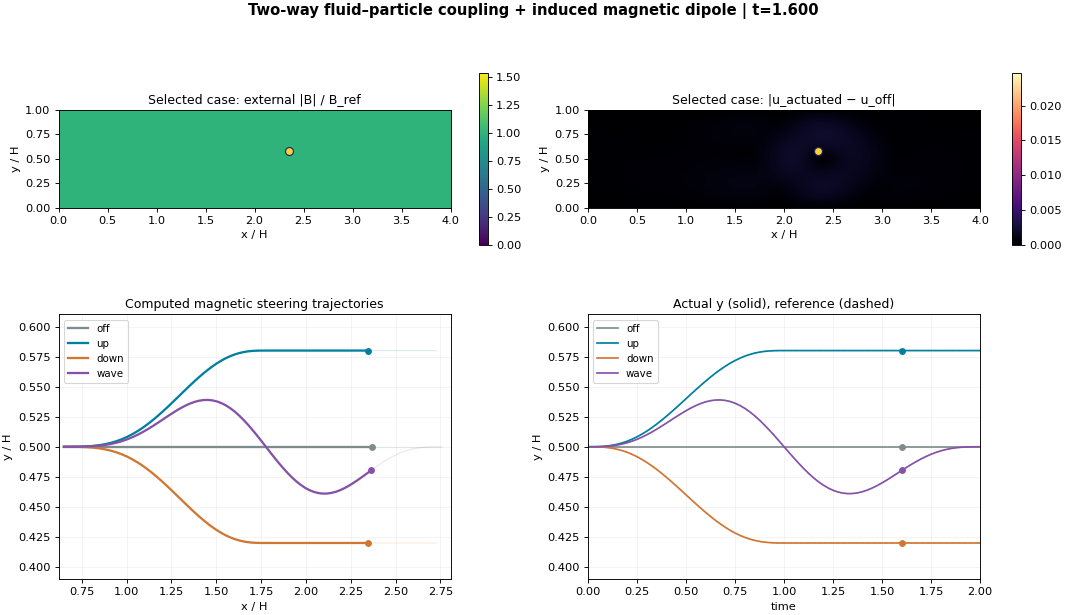
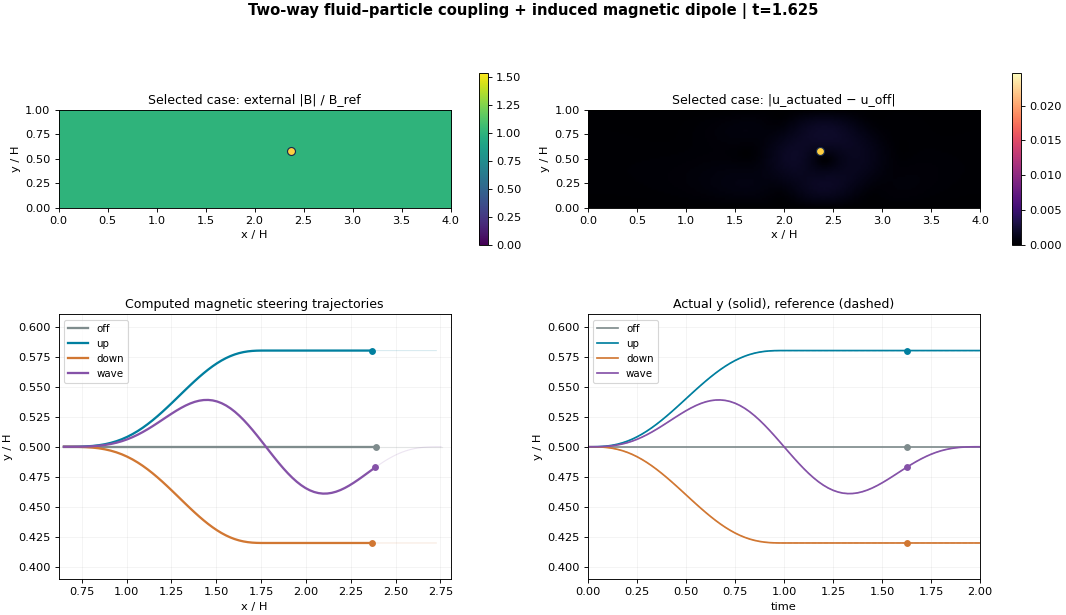
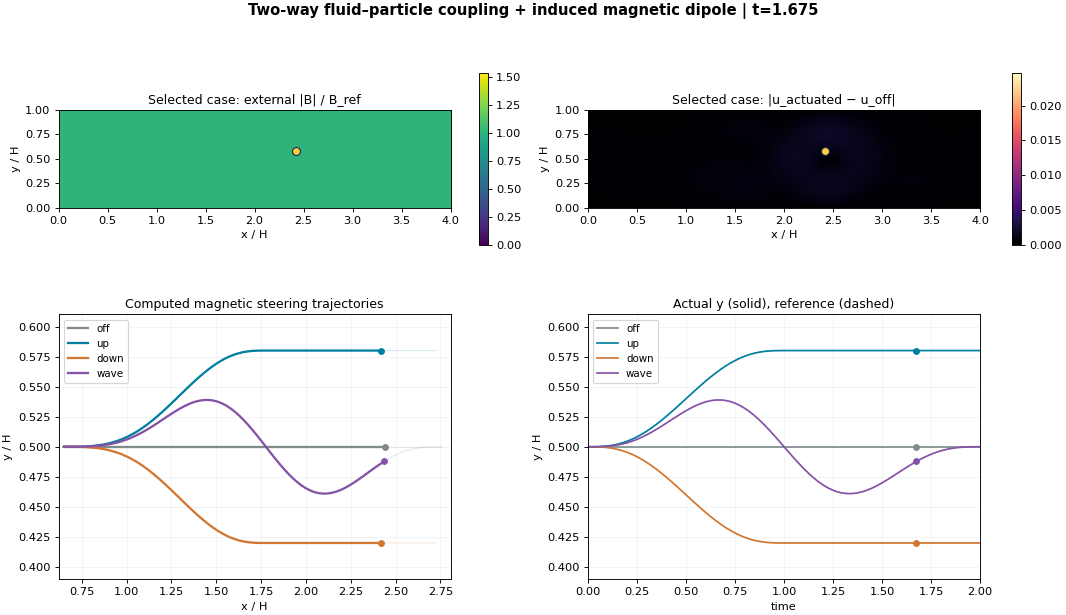
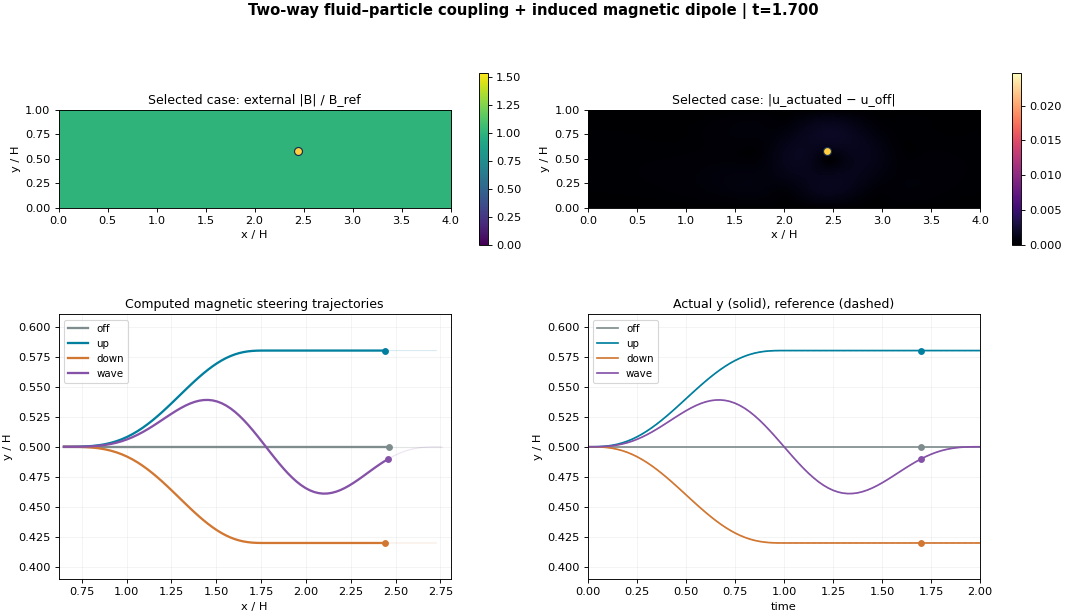
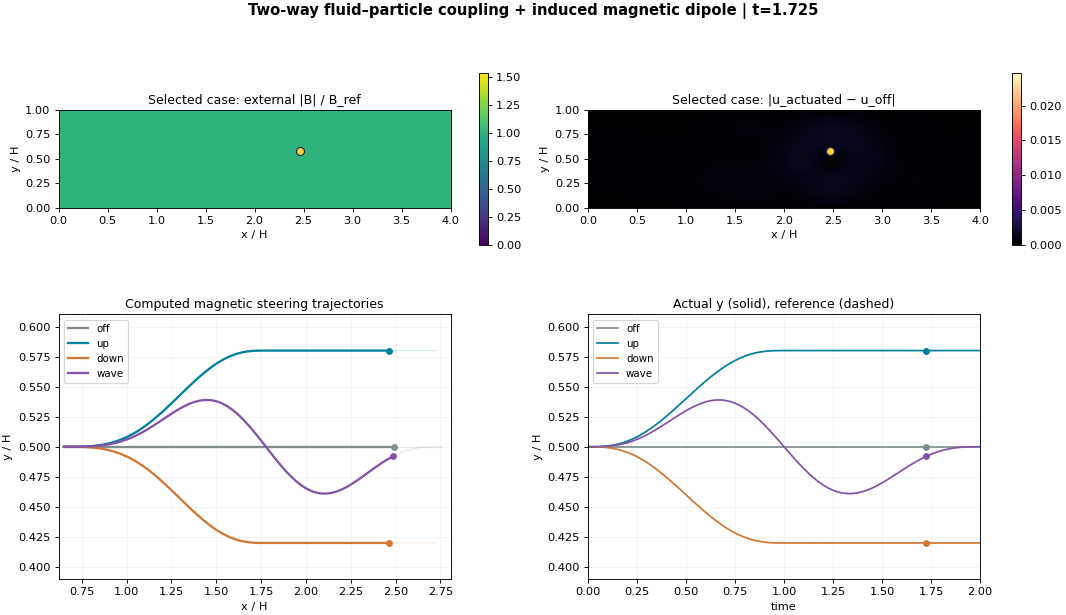
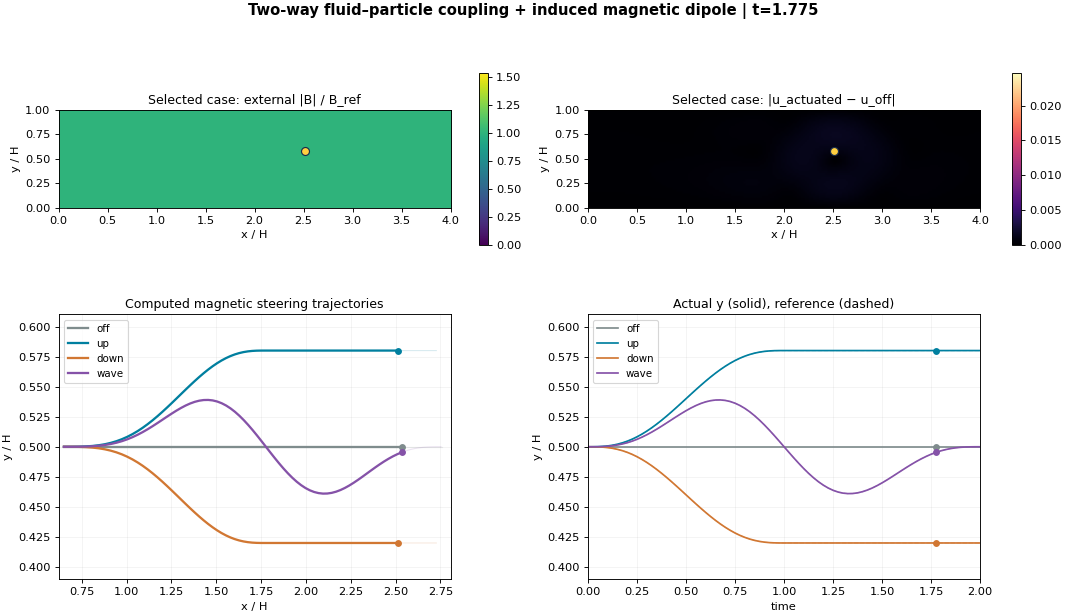
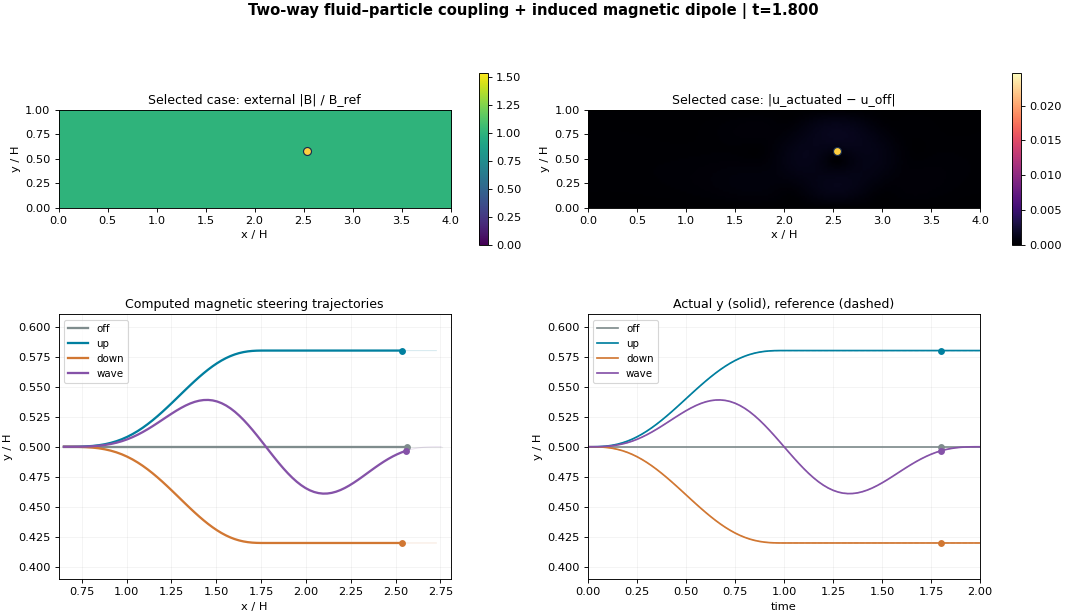
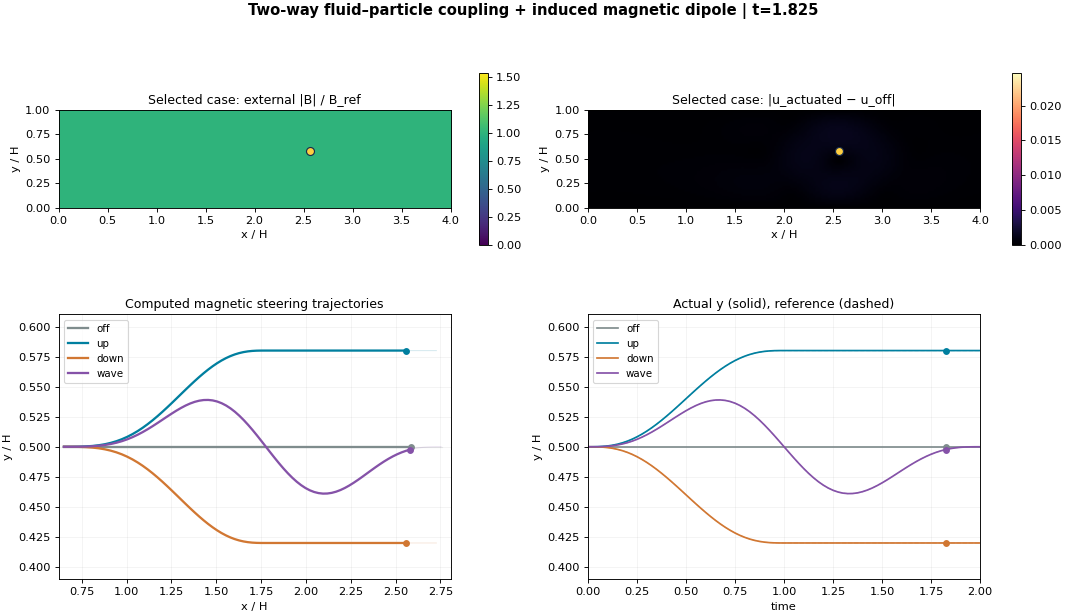
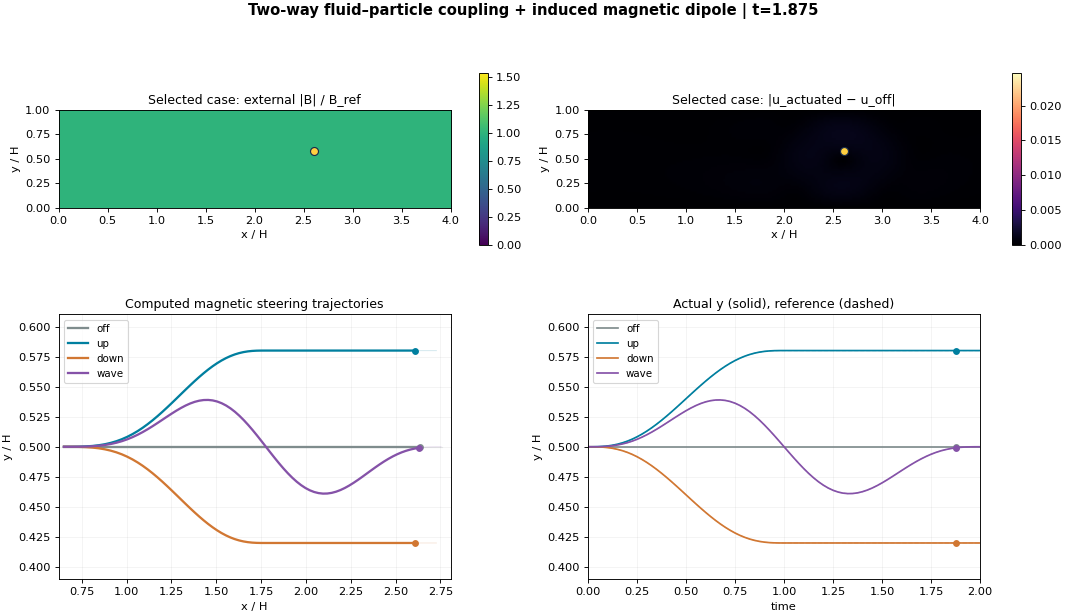
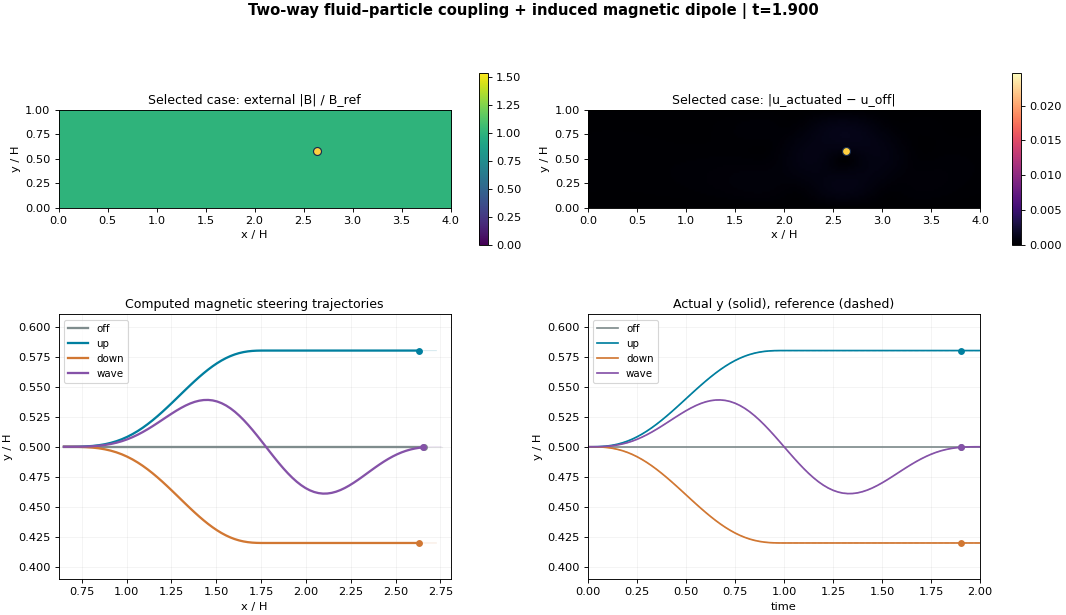
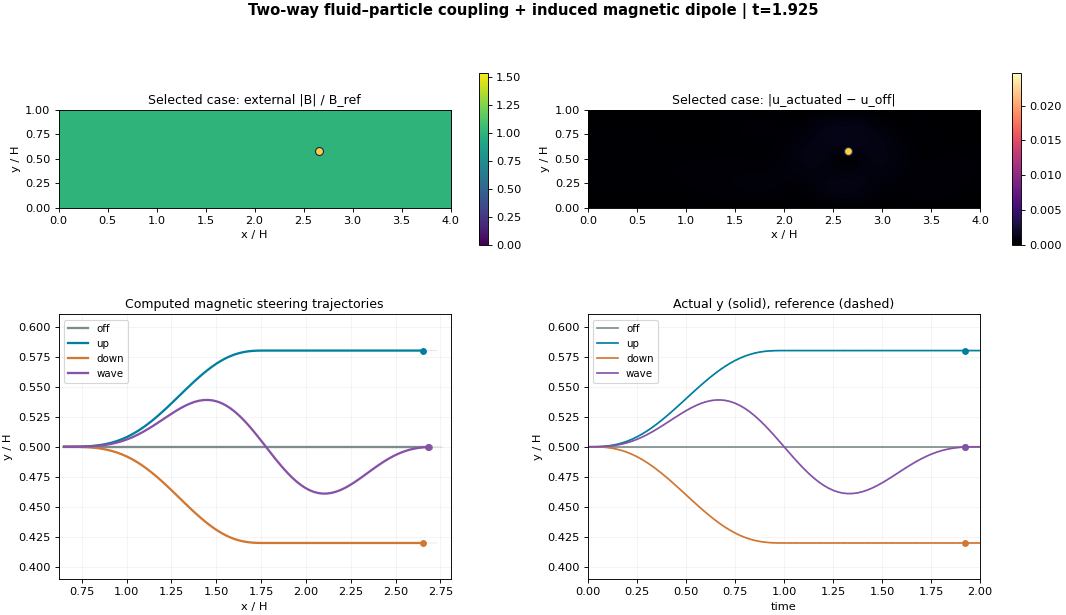
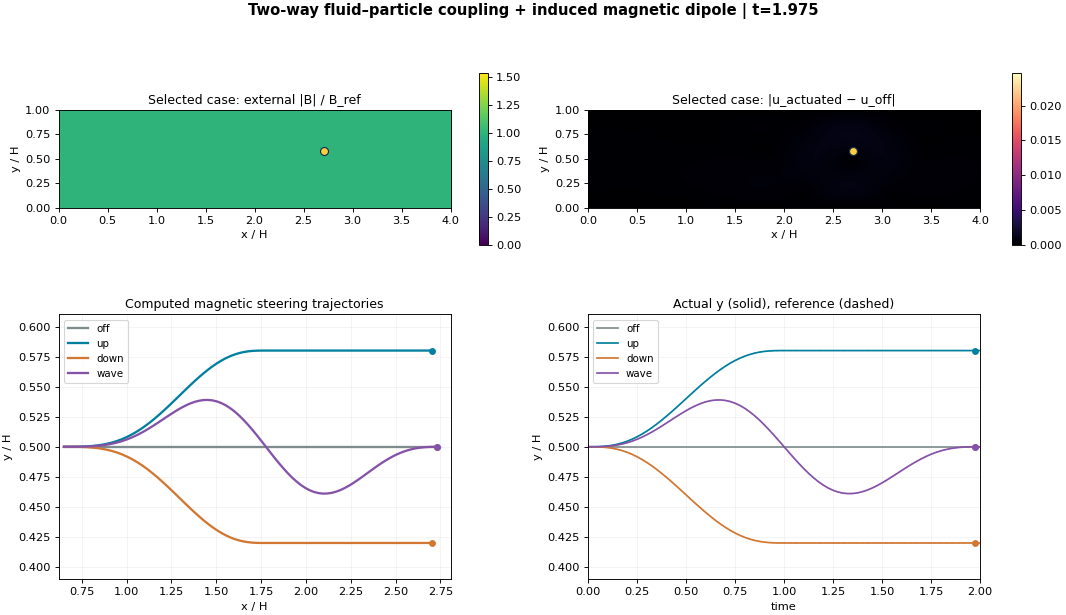
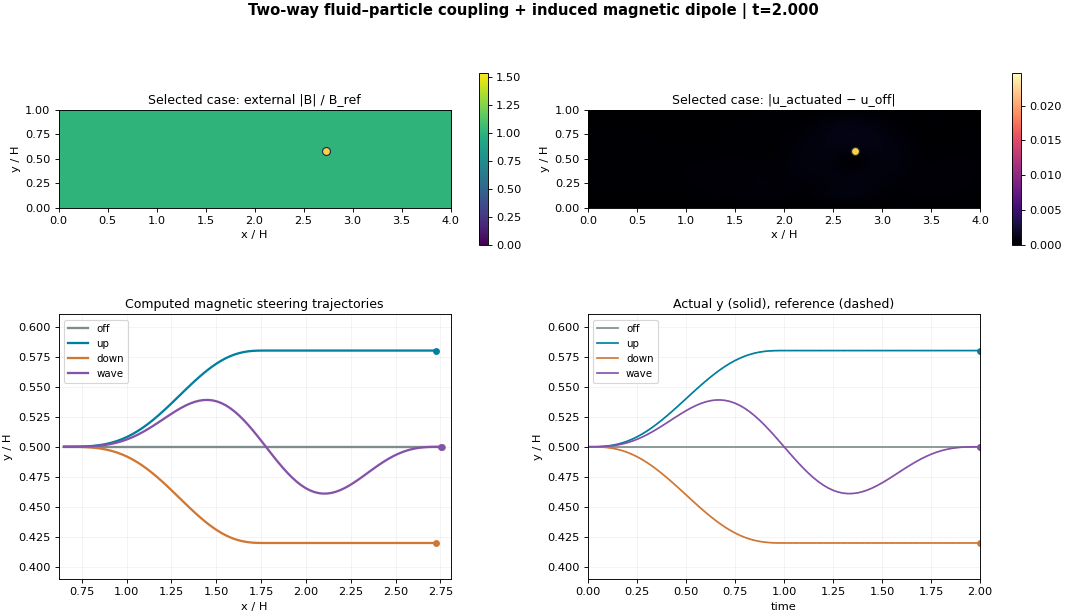

Total simulation + selected run + plots + animation: 303.9 s


In [8]:
animation_file = animate_magnetic(cases, selected, OUT)
display(HTML(animation_file.read_text()))
write_magnetic_readme(report, OUT)
print(f'Total simulation + selected run + plots + animation: {time.perf_counter()-wall_start:.1f} s')

## ۹. دانلود نتایج و گزارش آزمون‌ها

In [9]:
archive = OUT.parent/'Magnetic_Channel_Run_Outputs.zip'
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUT.rglob('*')):
        if p.is_file(): z.write(p,arcname=p.relative_to(OUT.parent))
print('ALL DEFAULT CHECKS PASSED:', report['all_passed'])
print('Checks:', len(report['checks']))
display(FileLink(str(archive)))

ALL DEFAULT CHECKS PASSED: True
Checks: 31


/kaggle/working/Magnetic_Channel_Run_Outputs.zip

## منابع و محدودهٔ اعتبار

- [COMSOL: Magnetophoretic Force](https://doc.comsol.com/6.4/doc/com.comsol.help.particle/particle_ug_fluid_flow.08.46.html): فرض‌های میدان خارجی و نیروی ناشی از گرادیان برای ذرهٔ خنثی و مغناطیس‌پذیر.
- [Simultaneous Magnetic Particle Imaging and Navigation ... (2019)](https://www.sciencedirect.com/science/article/pii/S0304885319320372): صورت نیروی القایی متناسب با گرادیان مربع میدان.

میدان هارمونیک و کنترل‌کنندهٔ این نوت‌بوک یک طراحی نمایشی مشخص‌اند و بازسازی دستگاه آزمایشگاهی این منابع نیستند.
آزمون‌ها صحت عددی همین مدل را می‌سنجند؛ اثر اشباع ماده، میدانِ خود ذره، نویز، برخورد و تطبیق با ذرهٔ واقعی نیاز به مدل و اعتبارسنجی جدا دارند.
